# Datalab I — Sprint 3: Data inspecteren en opschonen

**Opleiding:** Applied Data Science & AI — De Haagse Hogeschool  
**Dataset:** CBS, tabel `85618NED`  
**Datum:** 3 november 2026  

### Teamleden

| Studentnaam | Studentnummer |
|---|---|
| *Jamal Anches Gallego* | *25108328* |
| *John Shoghnani* | *24073806* |
| *Kaan Alhan* | *24132667* |
| *Dean Groise* | *23046910* |
| *Kyra van Bennekom* | *23115033* |
| *Freya den Hollander* | *24051772* |


## Doel en onderzoeksvraag

In dit notebook onderzoeken we de CBS-dataset op buurtniveau. We controleren de structuur en datakwaliteit, verwijderen kolommen volgens een vastgelegde aanpak en berekenen beschrijvende statistieken, gemeentetotalen en demografische percentages.

**Centrale vraag:** In hoeverre is de gebruikte CBS-buurtendataset geschikt als basis voor verdere analyse, en welke beperkingen moeten daarbij worden meegenomen?

### Leeswijzer

De stappen zijn achtereenvolgens: importeren, verkennen, filteren, opschonen, basisstatistieken, vergelijking met CBS en percentages. Bestaande code is ongewijzigd gebleven. Resultaten en conclusies moeten worden gecontroleerd na uitvoering van alle cellen.

**Bron:** Centraal Bureau voor de Statistiek (CBS), StatLine-tabel `85618NED`, opgehaald met `cbsodata`. Vermeld bij inlevering ook de raadpleegdatum en officiële tabeltitel.

# Datalab I 

**Opleiding:** Applied Data Science & AI — De Haagse Hogeschool  
**Dataset:** CBS, tabel `85618NED`  
**Datum:** 3 november 2026  

### Teamleden

| Studentnaam | Studentnummer |
|---|---|
| *Jamal Anches Gallego* | *25108328* |
| *John Shoghnani* | *24073806* |
| *Kaan Alhan* | *24132667* |
| *Dean Groise* | *23046910* |
| *Kyra van Bennekom* | *23115033* |
| *Freya den Hollander* | *24051772* |


# Sprint 3: Data inspecteren en opschonen

## Doel en onderzoeksvraag

In dit notebook onderzoeken we de CBS-dataset op buurtniveau. We controleren de structuur en datakwaliteit, verwijderen kolommen volgens een vastgelegde aanpak en berekenen beschrijvende statistieken, gemeentetotalen en demografische percentages.

**Centrale vraag:** In hoeverre is de gebruikte CBS-buurtendataset geschikt als basis voor verdere analyse, en welke beperkingen moeten daarbij worden meegenomen?

### Leeswijzer

De stappen zijn achtereenvolgens: importeren, verkennen, filteren, opschonen, basisstatistieken, vergelijking met CBS en percentages. Bestaande code is ongewijzigd gebleven. Resultaten en conclusies moeten worden gecontroleerd na uitvoering van alle cellen.

**Bron:** Centraal Bureau voor de Statistiek (CBS), StatLine-tabel `85618NED`, opgehaald met `cbsodata`. Vermeld bij inlevering ook de raadpleegdatum en officiële tabeltitel.

## 1. Benodigde bibliotheken

De onderstaande bestaande cel installeert de bibliotheek `cbsodata`. Voer de installatie alleen uit als dat in de gebruikte omgeving nodig is.

In [ ]:
!python -m pip install cbsodata


## 2. Dataset importeren

Met de CBS API wordt tabel `85618NED` opgehaald en omgezet naar een pandas-dataframe (`df`). De eerste selectie op `SoortRegio_2` maakt een dataframe met buurten. De omvang van de volledige dataset wordt weergegeven met `df.shape`.

In [ ]:
import cbsodata
import pandas as pd

# Gebruik een CBS-tabelcode (bijv. '83765ned' voor bevolkingsdata)
tabelcode = '85618NED'

# Haal de data direct op
data = cbsodata.get_data(tabelcode)
# Laad de data in een DataFrame
df = pd.DataFrame(data)

# Toon de eerste 5 rijen

buurten = df[df['SoortRegio_2'] == 'Buurt     ']
# door te filteren op de buurten, kunnen we de data beter analyseren en visualiseren, omdat buurten vaak specifieke kenmerken hebben die relevant zijn voor energiebedrijven om de energiebehoefte en -consumptie in kaart te brengen. Door te focussen op buurten kunnen we gerichte inzichten verkrijgen die kunnen helpen bij het optimaliseren van energievoorziening en -beleid.
df.shape


(18116, 128)

## 3. Eerste verkenning van de gegevens

We onderzoeken eerst welke regio-indelingen in de oorspronkelijke dataset voorkomen. Dit helpt om te controleren dat de latere analyses op één geografisch niveau worden uitgevoerd.

In [ ]:
df['SoortRegio_2'].unique() 

<ArrowStringArray>
['Land      ', 'Gemeente  ', 'Wijk      ', 'Buurt     ']
Length: 4, dtype: str

### 3.1 Ontbrekende waarden en datatypes

De bestaande code toont per kolom het aantal ontbrekende waarden en het datatype. Controleer bij de interpretatie of ontbrekende waarden voor de analyse relevante variabelen treffen. De comments in de code zijn voorlopige observaties en moeten overeenkomen met de daadwerkelijke uitvoer.

In [ ]:
print(buurten.isna().sum())
print(buurten.dtypes)

#5 rijen en 128 kolommen
#types zijn float64, int64 en str, dtype is object
#missende waarden zijn bij dekkingspercentage_124; 96, matevanstedelijkheid_125; 84 en omgevingsadressendichtheid_126; 84
#de eenheden die in deze dataset zijn gebruikt zijn: aantal, per 1000 inwoners, aantal inwoners per km2, euro's, percentages, kWh, m3, km2, km, ha, code


ID                                 0
WijkenEnBuurten                    0
Gemeentenaam_1                     0
SoortRegio_2                       0
Codering_3                         0
                                  ..
OppervlakteWater_122               0
MeestVoorkomendePostcode_123       0
Dekkingspercentage_124            96
MateVanStedelijkheid_125          84
Omgevingsadressendichtheid_126    84
Length: 128, dtype: int64
ID                                  int64
WijkenEnBuurten                       str
Gemeentenaam_1                        str
SoortRegio_2                          str
Codering_3                            str
                                   ...   
OppervlakteWater_122                int64
MeestVoorkomendePostcode_123          str
Dekkingspercentage_124            float64
MateVanStedelijkheid_125          float64
Omgevingsadressendichtheid_126    float64
Length: 128, dtype: object


### 3.2 Datasetbeschrijving en eerste statistieken

Met `describe()` bekijken we de numerieke verdelingen en met de volledige dataframeweergave de aanwezige kolommen. Voor het rubricniveau **Uitstekend** is daarnaast een controleerbaar overzicht per kolom nodig met betekenis, datatype, eenheid en ontbrekende waarden. De onderstaande code levert nog niet automatisch dat volledige overzicht.

In [ ]:
display(buurten.describe())
display(buurten.iloc[:,:])
#bescrijvingen per kolom:
#Bevolking: aantal inwoners, geslachten, leeftijdsgroepen, allochtonen (autochtoon, niet-westerse, westerse).
#Wonen: aantal woningen, koop/huurverhouding, WOZ-waarde, leegstand, sociale huurwoningen, huishoudensgrootte.
#Inkomen: gemiddeld en mediaan inkomen, lage-inkomenshuishoudens, bijstandsontvangers, AOW-ontvangers.
#Energie: gas- en elektriciteitsverbruik, zonnepanelen, energiearmoedehuishoudens.
#Vervoer: aantal motorvoertuigen en personenauto’s, elektrische auto’s, openbaar vervoergebruik, parkeerplaatsen.
#Veiligheid: misdrijven (totaal en per 1.000 inwoners), woninginbraken, verkeersongevallen.
#Onderwijs: aantal basisschool- en middelbare scholieren, hoogopgeleiden (HBO/WO).
#Bedrijven: aantal bedrijven, banen (voltijdsequivalenten), startende bedrijven, faillissementen.
#Milieu: groenoppervlak, stedelijkheid, oppervlakte buurt.
#Voorzieningen: afstand tot basisschool, middelbare school en kinderdagverblijf, aantal scholen en kinderopvanglocaties in de buurt.
#Identificatie: buurtcode, buurtnaam, wijkcode, wijknaam, gemeentecode, gemeentenaam, provincie.

,ID,AantalInwoners_5,Mannen_6,Vrouwen_7,k_0Tot15Jaar_8,k_15Tot25Jaar_9,k_25Tot45Jaar_10,k_45Tot65Jaar_11,k_65JaarOfOuder_12,Ongehuwd_13,...,AfstandTotGroteSupermarkt_116,AfstandTotKinderdagverblijf_117,AfstandTotSchool_118,ScholenBinnen3Km_119,OppervlakteTotaal_120,OppervlakteLand_121,OppervlakteWater_122,Dekkingspercentage_124,MateVanStedelijkheid_125,Omgevingsadressendichtheid_126
count,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,...,13668.000000,13668.000000,13668.000000,13668.000000,14421.000000,14421.000000,14421.000000,14325.000000,14337.000000,14337.000000
mean,9017.870883,1235.024270,613.673809,621.348728,189.147077,151.883711,312.513695,331.758200,249.710145,613.746273,...,1.593437,1.141308,1.195910,6.742706,243.259899,233.318078,9.928715,1.255079,3.553812,1224.455814
std,5236.883157,1609.106229,793.833311,816.858689,267.708033,223.740814,465.505961,418.982896,336.571257,873.336365,...,1.374546,0.983929,0.951566,6.584308,537.572591,519.699332,52.688322,0.836123,1.479556,1510.914445
min,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.100000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,4447.000000,185.000000,95.000000,90.000000,25.000000,20.000000,35.000000,55.000000,35.000000,80.000000,...,0.600000,0.500000,0.500000,2.000000,25.000000,24.000000,0.000000,1.000000,2.000000,175.000000
50%,9011.000000,710.000000,360.000000,355.000000,95.000000,80.000000,155.000000,200.000000,135.000000,325.000000,...,1.100000,0.800000,0.800000,5.000000,55.000000,53.000000,1.000000,1.000000,4.000000,767.000000
75%,13550.000000,1695.000000,840.000000,855.000000,255.000000,195.000000,415.000000,455.000000,340.000000,815.000000,...,2.200000,1.600000,1.600000,9.500000,191.000000,178.000000,4.000000,1.000000,5.000000,1731.000000
max,18115.000000,29265.000000,14025.000000,15240.000000,5095.000000,3905.000000,8670.000000,6870.000000,7870.000000,15565.000000,...,14.000000,13.100000,13.200000,55.300000,13016.000000,12816.000000,2296.000000,6.000000,5.000000,12559.000000


,ID,WijkenEnBuurten,Gemeentenaam_1,SoortRegio_2,Codering_3,IndelingswijzigingGemeenteWijkBuurt_4,AantalInwoners_5,Mannen_6,Vrouwen_7,k_0Tot15Jaar_8,...,AfstandTotKinderdagverblijf_117,AfstandTotSchool_118,ScholenBinnen3Km_119,OppervlakteTotaal_120,OppervlakteLand_121,OppervlakteWater_122,MeestVoorkomendePostcode_123,Dekkingspercentage_124,MateVanStedelijkheid_125,Omgevingsadressendichtheid_126
3,3,Annen,Aa en Hunze,Buurt,BU16800000,1,3450,1680,1775,495,...,0.5,0.8,2.5,252,252,0,9468,1.0,5.0,410.0
4,4,Verspreide huizen Annen,Aa en Hunze,Buurt,BU16800009,1,150,75,80,15,...,1.8,2.0,1.2,1226,1213,13,9468,1.0,5.0,59.0
6,6,Eext,Aa en Hunze,Buurt,BU16800100,1,1270,655,620,185,...,1.2,0.9,1.0,171,170,1,9463,1.0,5.0,147.0
7,7,Verspreide huizen Eext,Aa en Hunze,Buurt,BU16800109,1,180,90,90,10,...,2.0,2.1,1.3,1618,1614,4,9463,1.0,5.0,37.0
9,9,Anloo,Aa en Hunze,Buurt,BU16800200,1,325,165,160,45,...,2.5,0.5,2.0,57,57,0,9467,1.0,5.0,95.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18110,18110,Gerenlanden,Zwolle,Buurt,BU01935140,1,3025,1480,1540,535,...,0.5,0.5,12.0,58,55,2,8014,1.0,2.0,1958.0
18111,18111,Gerenbroek,Zwolle,Buurt,BU01935150,1,3040,1520,1515,550,...,0.5,0.5,11.7,49,47,2,8014,1.0,2.0,1613.0
18112,18112,Oude Mars,Zwolle,Buurt,BU01935160,1,200,105,95,45,...,1.8,1.8,7.5,45,43,2,8015,1.0,4.0,759.0
18114,18114,Windesheim,Zwolle,Buurt,BU01935200,1,410,200,205,85,...,0.3,0.3,1.0,53,53,0,8015,1.0,5.0,62.0


---
## 4. Consistente granulariteit: buurten

De dataset kan verschillende geografische niveaus bevatten. Door uitsluitend buurten te selecteren voorkomen we dat gegevens van gemeenten en buurten in dezelfde vergelijking worden behandeld. Dit is belangrijk omdat gemeenten buurten omvatten en anders dubbeltellingen of misleidende vergelijkingen kunnen ontstaan.


## Data opschonen

### 1. Dataset inspecteren


We filteren op alleen buurten zodat alle rijen op hetzelfde niveau zitten en we geen buurten met hele gemeenten optellen of vergelijken.

In [ ]:
# Dataframe buurten maken
buurten = df[df['SoortRegio_2'].str.strip() == 'Buurt']

In [ ]:
buurten.info()

<class 'pandas.DataFrame'>
Index: 14421 entries, 3 to 18115
Columns: 128 entries, ID to Omgevingsadressendichtheid_126
dtypes: float64(79), int64(43), str(6)
memory usage: 15.4 MB


### 4.1 Keuzes bij het opschonen

De bestaande werkwijze verwijdert kolommen wanneer meer dan 30% van de waarden ontbreekt. Dat is een gekozen kwaliteitsdrempel, **geen algemeen bewezen standaard**. Voor een beoordeling op *Uitstekend* moet deze keuze nog worden onderbouwd met een passende bron of een analyse van de gevolgen van verschillende drempels.

Daarnaast worden drie administratieve kolommen verwijderd. Controleer dat de kolommen die nodig zijn voor identificatie, koppeling en toekomstige energieanalyses behouden blijven.

### Waarom buurten filteren en data opschonen?
- **Alleen buurten:** We vergelijken alleen buurten met elkaar en geen gemeenten of landsdelen, zodat alle rijen op hetzelfde niveau liggen (consistente granulariteit).
- **Drempelwaarde lege vakjes (30%):** Als meer dan 30% van de gegevens ontbreekt, vinden wij de kolom te onbetrouwbaar om mee te rekenen.
- **Relevante kolommen:** Kenmerken zoals woningtype (bijv. tussenwoning, appartement, vrijstaand) en huishoudensgrootte houden we, omdat die direct invloed hebben op stroomverbruik.
- **Niet-relevante kolommen:** Administratieve kolommen zoals 'ID', 'Codering_3' en 'SoortRegio_2' hebben geen voorspellende waarde en worden verwijderd.

### 4.2 Opschoning uitvoeren en controleren

De code maakt `buurten_schoon` en vergelijkt het aantal rijen en kolommen vóór en na de opschoning. Noteer op basis van de uitvoer hoeveel kolommen daadwerkelijk zijn verwijderd en of het aantal buurten gelijk is gebleven.

In [ ]:
# 1. Kolommen met meer dan 30% ontbrekende waarden verwijderen
grens = 0.70 * len(buurten)
buurten_schoon = buurten.dropna(thresh=grens, axis=1)

# 2. Niet-relevante kolommen verwijderen
nutteloos = ['ID', 'Codering_3', 'SoortRegio_2']
buurten_schoon = buurten_schoon.drop(columns=[col for col in nutteloos if col in buurten_schoon.columns])

# 3. Eindresultaat controleren
print("Voor opschonen:", buurten.shape)
print("Na opschonen:", buurten_schoon.shape)

Voor opschonen: (14421, 128)
Na opschonen: (14421, 106)


---
## 5. Basisstatistieken

In dit onderdeel worden de basisstatistieken, gemeentetotalen en percentages berekend met de bestaande codecellen.


### 5.1 Beschrijvende basisstatistieken

#### Basisstatistieken

**Basisstatistieken berekenen**

Om de dataset verder te verkennen, berekenen we de basisstatistieken van alle numerieke kolommen uit het opgeschoonde dataframe buurten_schoon.

Per numerieke kolom berekenen we:

**Minimum:** De laagste waarde.

**Maximum:** De hoogste waarde.

**Gemiddelde:** De som van alle waarden gedeeld door het aantal beschikbare waarden.

**Mediaan:** De middelste waarde wanneer alle waarden van laag naar hoog worden gesorteerd.

Ontbrekende waarden worden automatisch buiten de berekeningen gehouden. De resultaten worden weergegeven in een Markdown-tabel, zodat de verschillende variabelen overzichtelijk vergeleken kunnen worden.

In [ ]:
# Basisstatistieken:

## Dean
# Minimum: De laagste waarde.
# Maximum: De hoogste waarde.
# Gemiddelde: De som van alle waarden gedeeld door het aantal beschikbare waarden.
# Mediaan: De middelste waarde wanneer alle waarden van laag naar hoog worden gesorteerd.

# Basisstatistieken berekenen voor alle numerieke kolommen

# Controleer eerst of de opgeschoonde dataset beschikbaar is.
# Deze variabele wordt aangemaakt in de cel "Kolommen opschonen" hierboven.
if "buurten_schoon" not in globals():
    raise RuntimeError(
        "De dataset 'buurten_schoon' bestaat nog niet. Voer eerst de eerdere cellen uit, "
        "met name de cel waarin 'buurten_schoon' wordt aangemaakt. "
        "Kies eventueel Kernel > Restart Kernel and Run All Cells."
    )

# Selecteer alle numerieke kolommen uit de opgeschoonde dataset
numerieke_kolommen = buurten_schoon.select_dtypes(include="number").columns

if len(numerieke_kolommen) == 0:
    raise ValueError("Er zijn geen numerieke kolommen gevonden in 'buurten_schoon'.")

# Bereken minimum, maximum, gemiddelde en mediaan per numerieke kolom
basisstatistieken = buurten_schoon[numerieke_kolommen].agg(
    ["min", "max", "mean", "median"]
).T

# Geef de statistieken Nederlandse kolomnamen en rond af op twee decimalen
basisstatistieken = basisstatistieken.rename(columns={
    "min": "Minimum",
    "max": "Maximum",
    "mean": "Gemiddelde",
    "median": "Mediaan"
}).round(2)

# Maak zelf een Markdown-tabel. Hiervoor is de extra package 'tabulate' niet nodig.
def dataframe_naar_markdown(dataframe):
    tabel = dataframe.copy()
    tabel.insert(0, "Numerieke kolom", tabel.index.astype(str))

    def formatteer_waarde(waarde):
        if pd.isna(waarde):
            return "—"
        return str(waarde).replace("|", r"\|").replace("\n", " ")

    kop = "| " + " | ".join(formatteer_waarde(kolom) for kolom in tabel.columns) + " |"
    scheiding = "| " + " | ".join("---" for _ in tabel.columns) + " |"
    rijen = [
        "| " + " | ".join(formatteer_waarde(waarde) for waarde in rij) + " |"
        for rij in tabel.itertuples(index=False, name=None)
    ]
    return "\n".join([kop, scheiding] + rijen)

from IPython.display import display, Markdown

display(Markdown(dataframe_naar_markdown(basisstatistieken)))

| Numerieke kolom | Minimum | Maximum | Gemiddelde | Mediaan |
| --- | --- | --- | --- | --- |
| AantalInwoners_5 | 0.0 | 29265.0 | 1235.02 | 710.0 |
| Mannen_6 | 0.0 | 14025.0 | 613.67 | 360.0 |
| Vrouwen_7 | 0.0 | 15240.0 | 621.35 | 355.0 |
| k_0Tot15Jaar_8 | 0.0 | 5095.0 | 189.15 | 95.0 |
| k_15Tot25Jaar_9 | 0.0 | 3905.0 | 151.88 | 80.0 |
| k_25Tot45Jaar_10 | 0.0 | 8670.0 | 312.51 | 155.0 |
| k_45Tot65Jaar_11 | 0.0 | 6870.0 | 331.76 | 200.0 |
| k_65JaarOfOuder_12 | 0.0 | 7870.0 | 249.71 | 135.0 |
| Ongehuwd_13 | 0.0 | 15565.0 | 613.75 | 325.0 |
| Gehuwd_14 | 0.0 | 9200.0 | 465.24 | 280.0 |
| Gescheiden_15 | 0.0 | 3100.0 | 96.19 | 45.0 |
| Verweduwd_16 | 0.0 | 2075.0 | 59.89 | 25.0 |
| Nederland_17 | 0.0 | 16390.0 | 899.94 | 550.0 |
| EuropaExclusiefNederland_18 | 0.0 | 4365.0 | 112.11 | 45.0 |
| BuitenEuropa_19 | 0.0 | 12980.0 | 222.97 | 45.0 |
| Nederland_20 | 0.0 | 16390.0 | 899.91 | 550.0 |
| EuropaExclusiefNederland_21 | 0.0 | 1060.0 | 41.95 | 20.0 |
| BuitenEuropa_22 | 0.0 | 6310.0 | 100.63 | 20.0 |
| EuropaExclusiefNederland_23 | 0.0 | 3790.0 | 70.17 | 20.0 |
| BuitenEuropa_24 | 0.0 | 6670.0 | 122.33 | 25.0 |
| GeboorteTotaal_25 | 0.0 | 320.0 | 11.38 | 5.0 |
| GeboorteRelatief_26 | 0.0 | 235.0 | 7.96 | 8.0 |
| SterfteTotaal_27 | 0.0 | 455.0 | 11.77 | 5.0 |
| SterfteRelatief_28 | 0.0 | 551.0 | 8.95 | 6.0 |
| HuishoudensTotaal_29 | 0.0 | 14180.0 | 573.39 | 310.0 |
| Eenpersoonshuishoudens_30 | 0.0 | 7485.0 | 226.42 | 90.0 |
| HuishoudensZonderKinderen_31 | 0.0 | 3265.0 | 163.59 | 95.0 |
| HuishoudensMetKinderen_32 | 0.0 | 4650.0 | 183.43 | 100.0 |
| GemiddeldeHuishoudensgrootte_33 | 1.0 | 6.0 | 2.27 | 2.3 |
| Bevolkingsdichtheid_34 | 0.0 | 55375.0 | 3239.39 | 2001.0 |
| Woningvoorraad_35 | 0.0 | 14277.0 | 563.43 | 305.0 |
| GemiddeldeWOZWaardeVanWoningen_36 | 34.0 | 2236.0 | 415.88 | 388.0 |
| PercentageEengezinswoning_37 | 0.0 | 100.0 | 76.21 | 87.0 |
| PercentageMeergezinswoning_38 | 0.0 | 100.0 | 23.79 | 13.0 |
| PercentageBewoond_39 | 0.0 | 100.0 | 94.53 | 96.0 |
| PercentageOnbewoond_40 | 0.0 | 100.0 | 5.47 | 4.0 |
| Koopwoningen_41 | 0.0 | 100.0 | 68.09 | 74.0 |
| HuurwoningenTotaal_42 | 0.0 | 100.0 | 31.77 | 26.0 |
| InBezitWoningcorporatie_43 | 0.0 | 100.0 | 18.33 | 13.0 |
| InBezitOverigeVerhuurders_44 | 0.0 | 100.0 | 13.44 | 9.0 |
| EigendomOnbekend_45 | 0.0 | 33.0 | 0.13 | 0.0 |
| BouwjaarVoor2000_46 | 0.0 | 100.0 | 80.35 | 88.0 |
| BouwjaarVanaf2000_47 | 0.0 | 100.0 | 19.65 | 12.0 |
| GemiddeldeElektriciteitsleveringTotaal_48 | 890.0 | 8310.0 | 3002.02 | 2830.0 |
| VrijstaandeWoning_53 | 1560.0 | 8310.0 | 3932.02 | 3900.0 |
| Huurwoning_54 | 790.0 | 6380.0 | 2347.54 | 2080.0 |
| EigenWoning_55 | 1380.0 | 8310.0 | 3239.11 | 3090.0 |
| GemiddeldAardgasverbruikTotaal_56 | 0.0 | 3540.0 | 1007.5 | 990.0 |
| VrijstaandeWoning_61 | 0.0 | 4010.0 | 1363.63 | 1350.0 |
| Huurwoning_62 | 0.0 | 2760.0 | 875.38 | 800.0 |
| EigenWoning_63 | 0.0 | 3530.0 | 1061.61 | 1060.0 |
| LeerlingenPo_65 | 0.0 | 2810.0 | 101.58 | 50.0 |
| LeerlingenVoInclVavo_66 | 0.0 | 1490.0 | 66.08 | 40.0 |
| StudentenMboExclExtranei_67 | 0.0 | 1100.0 | 32.62 | 20.0 |
| StudentenHbo_68 | 0.0 | 1240.0 | 31.29 | 10.0 |
| StudentenWo_69 | 0.0 | 2280.0 | 22.32 | 0.0 |
| WerkzameBeroepsbevolking_73 | 0.0 | 13290.0 | 662.03 | 380.0 |
| Nettoarbeidsparticipatie_74 | 14.0 | 95.0 | 72.71 | 73.0 |
| AantalInkomensontvangers_79 | 0.0 | 22500.0 | 996.45 | 600.0 |
| GemiddeldInkomenPerInkomensontvanger_80 | 7.8 | 151.3 | 40.55 | 39.0 |
| GemiddeldInkomenPerInwoner_81 | 7.4 | 108.0 | 33.73 | 32.7 |
| k_40PersonenMetLaagsteInkomen_82 | 8.0 | 93.3 | 39.42 | 39.0 |
| k_20PersonenMetHoogsteInkomen_83 | 0.0 | 65.7 | 20.69 | 19.8 |
| k_40HuishoudensMetLaagsteInkomen_85 | 0.9 | 100.0 | 35.64 | 33.1 |
| k_20HuishoudensMetHoogsteInkomen_86 | 0.0 | 79.8 | 23.14 | 21.3 |
| HuishoudensMetEenLaagInkomen_87 | 0.0 | 45.1 | 3.3 | 2.6 |
| HuishOnderOfRondSociaalMinimum_88 | 0.0 | 38.2 | 5.27 | 4.1 |
| HuishoudensTot110VanSociaalMinimum_89 | 0.0 | 58.7 | 7.94 | 6.2 |
| HuishoudensTot120VanSociaalMinimum_90 | 0.0 | 70.9 | 10.14 | 8.2 |
| MediaanVermogenVanParticuliereHuish_91 | -6.1 | 3016.0 | 234.09 | 207.6 |
| PersonenPerSoortUitkeringBijstand_92 | 0.0 | 1790.0 | 31.12 | 10.0 |
| PersonenPerSoortUitkeringAO_93 | 0.0 | 1470.0 | 59.87 | 30.0 |
| PersonenPerSoortUitkeringWW_94 | 0.0 | 280.0 | 11.03 | 10.0 |
| PersonenPerSoortUitkeringAOW_95 | 0.0 | 7220.0 | 253.03 | 150.0 |
| WmoClienten_98 | 10.0 | 3580.0 | 117.45 | 70.0 |
| WmoClientenRelatief_99 | 4.0 | 896.0 | 69.23 | 58.0 |
| BedrijfsvestigingenTotaal_100 | 0.0 | 5585.0 | 163.54 | 100.0 |
| ALandbouwBosbouwEnVisserij_101 | 0.0 | 385.0 | 5.88 | 0.0 |
| BFNijverheidEnEnergie_102 | 0.0 | 1285.0 | 26.73 | 15.0 |
| GIHandelEnHoreca_103 | 0.0 | 1055.0 | 31.24 | 15.0 |
| HJVervoerInformatieEnCommunicatie_104 | 0.0 | 610.0 | 14.23 | 5.0 |
| KLFinancieleDienstenOnroerendGoed_105 | 0.0 | 500.0 | 14.04 | 10.0 |
| MNZakelijkeDienstverlening_106 | 0.0 | 1965.0 | 43.19 | 25.0 |
| OQOverheidOnderwijsEnZorg_107 | 0.0 | 650.0 | 31.05 | 20.0 |
| RUCultuurRecreatieOverigeDiensten_108 | 0.0 | 535.0 | 20.38 | 10.0 |
| PersonenautoSTotaal_109 | 0.0 | 62120.0 | 593.91 | 370.0 |
| PersonenautoSBrandstofBenzine_110 | 0.0 | 33740.0 | 472.35 | 290.0 |
| PersonenautoSOverigeBrandstof_111 | 0.0 | 32750.0 | 121.55 | 75.0 |
| PersonenautoSPerHuishouden_112 | 0.0 | 2.5 | 1.17 | 1.2 |
| PersonenautoSNaarOppervlakte_113 | 0.0 | 14129.0 | 1603.56 | 1468.0 |
| Motorfietsen_114 | 0.0 | 605.0 | 47.75 | 30.0 |
| AfstandTotHuisartsenpraktijk_115 | 0.0 | 13.5 | 1.72 | 1.2 |
| AfstandTotGroteSupermarkt_116 | 0.0 | 14.0 | 1.59 | 1.1 |
| AfstandTotKinderdagverblijf_117 | 0.0 | 13.1 | 1.14 | 0.8 |
| AfstandTotSchool_118 | 0.1 | 13.2 | 1.2 | 0.8 |
| ScholenBinnen3Km_119 | 0.0 | 55.3 | 6.74 | 5.0 |
| OppervlakteTotaal_120 | 0.0 | 13016.0 | 243.26 | 55.0 |
| OppervlakteLand_121 | 0.0 | 12816.0 | 233.32 | 53.0 |
| OppervlakteWater_122 | 0.0 | 2296.0 | 9.93 | 1.0 |
| Dekkingspercentage_124 | 1.0 | 6.0 | 1.26 | 1.0 |
| MateVanStedelijkheid_125 | 1.0 | 5.0 | 3.55 | 4.0 |
| Omgevingsadressendichtheid_126 | 1.0 | 12559.0 | 1224.46 | 767.0 |


---
## 6. Vergelijking met officiële CBS-gemeentecijfers

De bestaande code telt inwonersaantallen per gemeente op uit de buurtgegevens en vergelijkt deze met gemeentecijfers uit de oorspronkelijke CBS-dataset. Het verschil wordt berekend als **eigen totaal minus CBS-totaal**.

**Interpretatie na uitvoering:** bespreek voor de getoonde gemeenten de grootte en richting van de verschillen. Afronding van buurtaantallen kan een verklaring zijn, maar mag niet zonder controle als enige oorzaak worden aangenomen.

###
Voor een selectie van gemeenten vergelijken we de opgesomde buurttotalen met de officiële gemeentecijfers van het CBS. Kleine verschillen ontstaan doordat het CBS buurtaantallen om privacyredenen afrondt op vijftallen; doordat deze afrondingen per afzonderlijke buurt worden opgeteld, cumuleert het afrondingsverschil vooral bij grotere gemeenten met veel buurten.

In [ ]:
# Basisstatistieken:

##kyra
# Totalen per gemeente 
# geschikte kolommen voor totalen selecteren
# totalen per gemeente berekenen .groupby()
# aantal inwoners per gemeeente  

import pandas as pd
#meetwaarden data set obs=observations
df_obs= pd.read_csv("Observations.csv", sep=";" )
#gebiedscodes & namen 
df_regios= pd.read_csv("WijkenEnBuurtenCodes.csv", sep=";")
#rijen & kolom namen 
print("Observattions:")
display(df_obs.head(3))

print("regio codes:")
display(df_regios.head(3))

#gegevens koppelen per gemeente 
df_totaal= pd.merge(df_obs, df_regios, how="left", left_on= "WijkenEnBuurten", right_on="Identifier")
display(df_totaal.head(5))

# filteren enkel data gemeente GM  (geschikte kolommen voor totalen selecteren)
df_totaal ["Value"]= pd.to_numeric(df_totaal["Value"], errors="coerce")
# aantal inwoners per gemeeente  
df_gemeente_inwoners= df_totaal[(df_totaal["DimensionGroupId"]== "GM") & (df_totaal["Measure"]=="T001036" )]
#groepeer per gemeente  (totalen per gemeente berekenen .groupby())
totalen_per_gemeente= (df_gemeente_inwoners.groupby("Title")["Value"].sum().reset_index())
display(totalen_per_gemeente.head())

Observattions:


,Id,Measure,WijkenEnBuurten,Value,StringValue,ValueAttribute
0,0,GM000C,NL00,NaN,Nederland,NaN
1,1,R00003,NL00,NaN,Land,NaN
2,2,R00004,NL00,NaN,NL00,NaN


regio codes:


,Identifier,DimensionGroupId,DimensionId,Index,Title,Description,DetailRegionCode
0,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
1,GM1680,GM,WijkenEnBuurten,2,Aa en Hunze,Gemeente 'Aa en Hunze' (GM1680),GM1680
2,WK168000,GM1680,WijkenEnBuurten,3,Wijk 00 Annen,Wijk 'Wijk 00 Annen' (WK168000) is een wijk in...,WK168000


,Id,Measure,WijkenEnBuurten,Value,StringValue,ValueAttribute,Identifier,DimensionGroupId,DimensionId,Index,Title,Description,DetailRegionCode
0,0,GM000C,NL00,NaN,Nederland,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
1,1,R00003,NL00,NaN,Land,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
2,2,R00004,NL00,NaN,NL00,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
3,3,T001036,NL00,17811291,NaN,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
4,4,3000,NL00,8850309,NaN,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN


,Title,Value
0,'s-Gravenhage,562839.0
1,'s-Hertogenbosch,158753.0
2,Aa en Hunze,25724.0
3,Aalsmeer,33063.0
4,Aalten,27244.0



---
## 7. Demografische percentages op buurtniveau

De bestaande code berekent percentages voor tien demografische variabelen. De formule is `aantal in groep / totaal aantal inwoners × 100`. De laatste controle telt de percentages mannen en vrouwen bij elkaar op.

**Interpretatie na uitvoering:** controleer of de percentages plausibel zijn, of buurten met nul inwoners tot ontbrekende of oneindige waarden leiden en of afronding afwijkingen van 100% kan verklaren.

In [ ]:

# 1. Eigen buurttotalen berekenen
buurten_schoon["AantalInwoners_5"] = pd.to_numeric(
    buurten_schoon["AantalInwoners_5"],
    errors="coerce"
)

eigen_totalen = (
    buurten_schoon
    .groupby("Gemeentenaam_1")["AantalInwoners_5"]
    .sum()
    .reset_index()
)

eigen_totalen.columns = ["Gemeente", "Eigen_Totaal"]
eigen_totalen["Gemeente"] = eigen_totalen["Gemeente"].astype(str).str.strip()


# 2. Officiele CBS-gemeentecijfers ophalen uit originele dataset
cbs_gemeenten = df[
    df["SoortRegio_2"].astype(str).str.strip() == "Gemeente"
].copy()

# Zorg ervoor dat inwonersaantallen numeriek zijn
cbs_gemeenten["AantalInwoners_5"] = pd.to_numeric(
    cbs_gemeenten["AantalInwoners_5"],
    errors="coerce"
)

# Alleen gemeentenaam en inwonersaantal behouden
cbs_totalen = cbs_gemeenten[
    ["Gemeentenaam_1", "AantalInwoners_5"]
].copy()

cbs_totalen.columns = ["Gemeente", "CBS_Totaal"]

cbs_totalen["Gemeente"] = (
    cbs_totalen["Gemeente"].astype(str).str.strip()
)


# 3. Eigen resultaten vergelijken met CBS
vergelijking = pd.merge(
    eigen_totalen,
    cbs_totalen,
    on="Gemeente",
    how="inner"
)

vergelijking["Verschil"] = (
    vergelijking["Eigen_Totaal"] - vergelijking["CBS_Totaal"]
)


# 4. Een selectie van gemeenten tonen
selectie = [
    "'s-Gravenhage",
    "Aa en Hunze",
    "Aalsmeer",
    "Almere"
]

vergelijking_selectie = vergelijking[
    vergelijking["Gemeente"].isin(selectie)
]

display(vergelijking_selectie)


,Gemeente,Eigen_Totaal,CBS_Totaal,Verschil
0,'s-Gravenhage,562490,562839,-349
2,Aa en Hunze,25700,25724,-24
3,Aalsmeer,33065,33063,2
10,Almere,222850,222825,25


## 8. Percentages per buurt berekenen

In deze stap berekenen we percentages van verschillende demografische groepen per buurt.

Hiervoor gebruiken we:
- het aantal inwoners als noemer
- de demografische aantallen als teller

Formule:

percentage = (aantal / totaal aantal inwoners) * 100

De percentages worden toegevoegd als nieuwe kolommen aan het dataframe.

In [ ]:
# Selecteer demografische kolommen
demografische_kolommen = [
    'Mannen_6',
    'Vrouwen_7',
    'k_0Tot15Jaar_8',
    'k_15Tot25Jaar_9',
    'k_25Tot45Jaar_10',
    'k_45Tot65Jaar_11',
    'k_65JaarOfOuder_12',
    'Ongehuwd_13',
    'Gehuwd_14',
    'Gescheiden_15'
]

# Zorg dat de kolommen numeriek zijn
buurten_schoon['AantalInwoners_5'] = pd.to_numeric(
    buurten_schoon['AantalInwoners_5'],
    errors='coerce'
)

for col in demografische_kolommen:

    buurten_schoon[col] = pd.to_numeric(
        buurten_schoon[col],
        errors='coerce'
    )

    # Nieuwe percentagekolom maken
    perc_colnaam = f"Perc_{col}"

    buurten_schoon[perc_colnaam] = (
        buurten_schoon[col] /
        buurten_schoon['AantalInwoners_5']
    ) * 100

# Nieuwe percentagekolommen tonen
percentagekolommen = [
    f"Perc_{col}" for col in demografische_kolommen
]

display(
    buurten_schoon[
        ['Gemeentenaam_1', 'WijkenEnBuurten', 'AantalInwoners_5']
        + percentagekolommen
    ].head()
)

# Controleren of percentages logisch zijn
buurten_schoon['Totaal_Percentage'] = (
    buurten_schoon['Perc_Mannen_6'] +
    buurten_schoon['Perc_Vrouwen_7']
)

# Controle tonen
display(
    buurten_schoon[
        ['WijkenEnBuurten', 'Totaal_Percentage']
    ].head()
)

,Gemeentenaam_1,WijkenEnBuurten,AantalInwoners_5,Perc_Mannen_6,Perc_Vrouwen_7,Perc_k_0Tot15Jaar_8,Perc_k_15Tot25Jaar_9,Perc_k_25Tot45Jaar_10,Perc_k_45Tot65Jaar_11,Perc_k_65JaarOfOuder_12,Perc_Ongehuwd_13,Perc_Gehuwd_14,Perc_Gescheiden_15
3,Aa en Hunze,Annen,3450,48.695652,51.449275,14.347826,10.289855,17.826087,30.579710,27.101449,40.434783,45.942029,7.391304
4,Aa en Hunze,Verspreide huizen Annen,150,50.000000,53.333333,10.000000,10.000000,10.000000,43.333333,30.000000,33.333333,56.666667,3.333333
6,Aa en Hunze,Eext,1270,51.574803,48.818898,14.566929,11.023622,22.047244,30.708661,21.653543,44.488189,43.307087,7.480315
7,Aa en Hunze,Verspreide huizen Eext,180,50.000000,50.000000,5.555556,8.333333,19.444444,30.555556,36.111111,41.666667,47.222222,8.333333
9,Aa en Hunze,Anloo,325,50.769231,49.230769,13.846154,9.230769,16.923077,35.384615,26.153846,38.461538,49.230769,9.230769


,WijkenEnBuurten,Totaal_Percentage
3,Annen,100.144928
4,Verspreide huizen Annen,103.333333
6,Eext,100.393701
7,Verspreide huizen Eext,100.000000
9,Anloo,100.000000



## 9. Bronnen en verantwoording

- Centraal Bureau voor de Statistiek (CBS), StatLine-tabel `85618NED`.
- Documentatie van `cbsodata`.


## Sprint 4

### Waarom correlaties berekenen en wat betekenen de cijfers?

* **Doel:** We willen zien welke kenmerken van een wijk echt invloed hebben op het stroomverbruik (`GemiddeldeElektriciteitsleveringTotaal_48`), zodat we weten met welke variabelen we straks het beste kunnen voorspellen.
* **Vuistregels (Cohen, 1988):** We kijken naar de Pearson-correlatie tussen -1 en +1; volgens de theorie van Cohen spreken we vanaf 0.5 (of onder de -0.5) van een sterk verband.
* **Wat de richting zegt:** Een positieve score betekent dat het verbruik meestijgt (bijvoorbeeld bij koopwoningen en hoog vermogen), terwijl een negatieve score juist betekent dat het verbruik daalt (zoals bij huurwoningen en corporatiebezit).

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

,GemiddeldeElektriciteitsleveringTotaal_48
EigenWoning_55,0.953541
Huurwoning_54,0.828967
PersonenautoSPerHuishouden_112,0.736332
MediaanVermogenVanParticuliereHuish_91,0.725682
k_20HuishoudensMetHoogsteInkomen_86,0.720708
Koopwoningen_41,0.695056
HuurwoningenTotaal_42,-0.694090
GemiddeldAardgasverbruikTotaal_56,0.682800
InBezitWoningcorporatie_43,-0.664778
MateVanStedelijkheid_125,0.659807


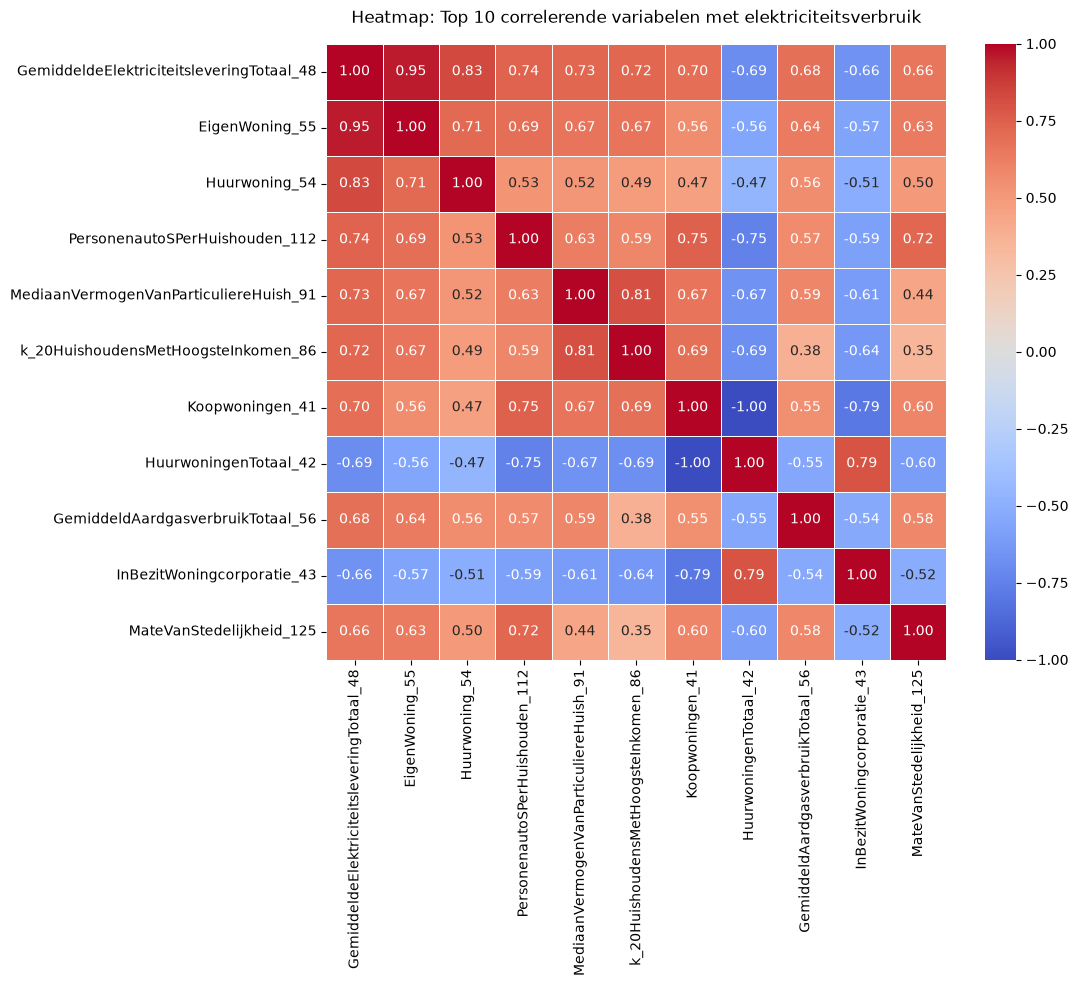

In [ ]:
# 1. Bepaal doelvariabele en bereken correlatiematrix
doel = 'GemiddeldeElektriciteitsleveringTotaal_48'
corr_matrix = buurten_schoon.corr(numeric_only=True)

# 2. Correlaties sorteren op absolute sterkte (+ en -)
correlaties = corr_matrix[[doel]].drop(index=doel)
correlaties['abs'] = correlaties[doel].abs()
top_10_labels = correlaties.sort_values(by='abs', ascending=False).head(10).index.tolist()

# Tabel tonen
display(correlaties.loc[top_10_labels, [doel]])

# 3. Vierkante Heatmap maken
matrix_vars = [doel] + top_10_labels
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix.loc[matrix_vars, matrix_vars],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Heatmap: Top 10 correlerende variabelen met elektriciteitsverbruik", pad=15)
plt.show()

# Sprint 4: Data exploratie

In Sprint 4 onderzoeken we patronen, verschillen en relaties in de CBS-buurtendataset. 
We berekenen eerst enkele basisstatistieken. Daarna onderzoeken we de correlaties tussen 
variabelen en het gemiddelde elektriciteitsverbruik. Tot slot maken we visualisaties en 
trekken we conclusies over het voorspellen van energieverbruik.

Voor deze analyses gebruiken we het opgeschoonde dataframe `buurten_schoon` uit Sprint 3.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Controleer of de opgeschoonde dataset bestaat
print("Aantal rijen en kolommen:", buurten_schoon.shape)

# Toon alle kolomnamen
display(pd.DataFrame(buurten_schoon.columns, columns=["Kolomnaam"]))

Aantal rijen en kolommen: (14421, 117)


,Kolomnaam
0,WijkenEnBuurten
1,Gemeentenaam_1
2,IndelingswijzigingGemeenteWijkBuurt_4
3,AantalInwoners_5
4,Mannen_6
...,...
112,Perc_k_65JaarOfOuder_12
113,Perc_Ongehuwd_13
114,Perc_Gehuwd_14
115,Perc_Gescheiden_15


## 4.2 Gemiddelde grootte van een huishouden

In deze stap bepalen we de gemiddelde grootte van huishoudens in Nederland. 
De gemiddelde huishoudgrootte geeft aan uit hoeveel personen een huishouden gemiddeld bestaat.

In [ ]:
# Zoek kolommen waarin informatie over huishoudensgrootte staat

[kolom for kolom in buurten_schoon.columns 
 if "Huishoud" in kolom or "huishoud" in kolom]

['HuishoudensTotaal_29',
 'Eenpersoonshuishoudens_30',
 'HuishoudensZonderKinderen_31',
 'HuishoudensMetKinderen_32',
 'GemiddeldeHuishoudensgrootte_33',
 'k_40HuishoudensMetLaagsteInkomen_85',
 'k_20HuishoudensMetHoogsteInkomen_86',
 'HuishoudensMetEenLaagInkomen_87',
 'HuishoudensTot110VanSociaalMinimum_89',
 'HuishoudensTot120VanSociaalMinimum_90',
 'PersonenautoSPerHuishouden_112']

In [ ]:
# Kolomnamen netjes maken
df.columns = df.columns.astype(str).str.strip()

# De kolom met huishoudgrootte automatisch zoeken
kolommen = [
    kolom for kolom in df.columns
    if "huishoud" in kolom.lower() and "grootte" in kolom.lower()
]

print("Gevonden kolom:", kolommen)

# Alleen buurten selecteren
buurten = df[
    df["SoortRegio_2"].astype(str).str.strip() == "Buurt"
].copy()

# De gevonden kolom gebruiken
kolom = kolommen[0]

# Waarden omzetten naar getallen
buurten[kolom] = pd.to_numeric(
    buurten[kolom],
    errors="coerce"
)

# Gemiddelde berekenen
gemiddelde = buurten[kolom].mean()

print("De gemiddelde huishoudgrootte is:", round(gemiddelde, 2), "personen per huishouden.")

Gevonden kolom: ['GemiddeldeHuishoudensgrootte_33']
De gemiddelde huishoudgrootte is: 2.27 personen per huishouden.


### Interpretatie

De gemiddelde huishoudgrootte in de dataset is **2,27 personen per huishouden**. 
Dit betekent dat een huishouden in de onderzochte buurten gemiddeld uit ongeveer 2 personen bestaat.

## 4.3 Inwoners per stedelijkheidscategorie

In deze stap onderzoeken we hoeveel inwoners er in iedere stedelijkheidscategorie wonen. 
Hiervoor groeperen we het aantal inwoners op basis van de mate van stedelijkheid.

In [ ]:
# Bekijk de kolommen die nodig zijn voor deze analyse
[kolom for kolom in buurten_schoon.columns 
 if "Inwoners" in kolom or "Stedelijk" in kolom or "stedelijk" in kolom]

['AantalInwoners_5', 'MateVanStedelijkheid_125']

In [ ]:
# Bekijk welke waarden in de stedelijkheidskolom staan
display(
    buurten_schoon["MateVanStedelijkheid_125"]
    .value_counts(dropna=False)
    .sort_index()
)

MateVanStedelijkheid_125
1.0    1860
2.0    2412
3.0    1921
4.0    2216
5.0    5928
NaN      84
Name: count, dtype: int64

In [ ]:
inwoners_per_stedelijkheid = (
    buurten_schoon
    .groupby("MateVanStedelijkheid_125")["AantalInwoners_5"]
    .sum()
    .reset_index()
)

inwoners_per_stedelijkheid.columns = [
    "Stedelijkheidscategorie",
    "Aantal inwoners"
]

display(inwoners_per_stedelijkheid)

,Stedelijkheidscategorie,Aantal inwoners
0,1.0,4432010
1,2.0,4492930
2,3.0,3251570
3,4.0,2819245
4,5.0,2814530


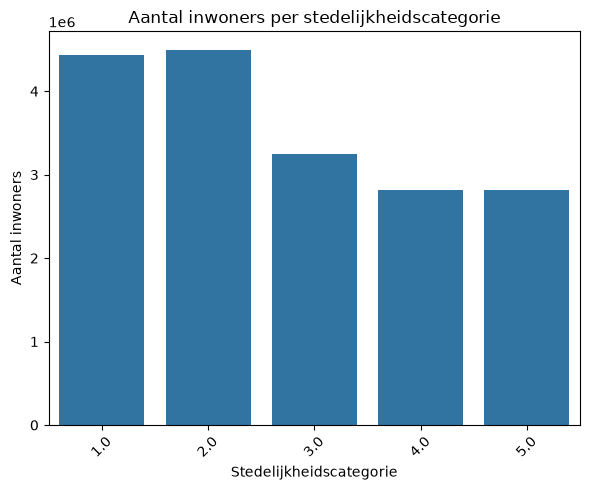

In [ ]:
plt.figure(figsize=(6, 5))

sns.barplot(
    data=inwoners_per_stedelijkheid,
    x="Stedelijkheidscategorie",
    y="Aantal inwoners"
)

plt.title("Aantal inwoners per stedelijkheidscategorie")
plt.xlabel("Stedelijkheidscategorie")
plt.ylabel("Aantal inwoners")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretatie

De grafiek laat het aantal inwoners per stedelijkheidscategorie zien. 
Stedelijkheidscategorie 2 heeft het hoogste aantal inwoners, gevolgd door categorie 1. 
Categorie 3 heeft minder inwoners dan categorie 1 en 2. De categorieën 4 en 5 hebben 
het laagste aantal inwoners.

De verschillen kunnen worden verklaard doordat niet iedere stedelijkheidscategorie 
evenveel inwoners of buurten bevat. De categorieën zijn weergegeven als codes van 1 
tot en met 5. Volgens de CBS-metadata moeten deze codes nog worden gekoppeld aan de 
bijbehorende omschrijvingen van de stedelijkheidscategorieën.






## 4.4 Gemiddeld elektriciteitsverbruik

In deze stap berekenen we het gemiddelde elektriciteitsverbruik per huishouden 
voor de buurten in de dataset. Deze variabele gebruiken we later als doelvariabele 
bij het onderzoeken van correlaties en het maken van voorspellingen.

In [ ]:
kolom_elektriciteitsverbruik = "GemiddeldeElektriciteitsleveringTotaal_48"

# Waarden omzetten naar getallen
buurten_schoon[kolom_elektriciteitsverbruik] = pd.to_numeric(
    buurten_schoon[kolom_elektriciteitsverbruik],
    errors="coerce"
)

# Gemiddeld elektriciteitsverbruik berekenen
gemiddeld_elektriciteitsverbruik = buurten_schoon[
    kolom_elektriciteitsverbruik
].mean()

print(
    "Het gemiddelde elektriciteitsverbruik is:",
    round(gemiddeld_elektriciteitsverbruik, 2),
    "kWh per huishouden."
)

Het gemiddelde elektriciteitsverbruik is: 3002.02 kWh per huishouden.


### Interpretatie

Het gemiddelde elektriciteitsverbruik bedraagt ongeveer **3002.02 kWh per huishouden**. 
Dit gemiddelde gebruiken we als uitgangspunt voor de verdere analyses in Sprint 4. 
In de volgende stappen onderzoeken we welke variabelen samenhangen met dit energieverbruik. 

## 4.12 Aantal inwoners per gemeente

342


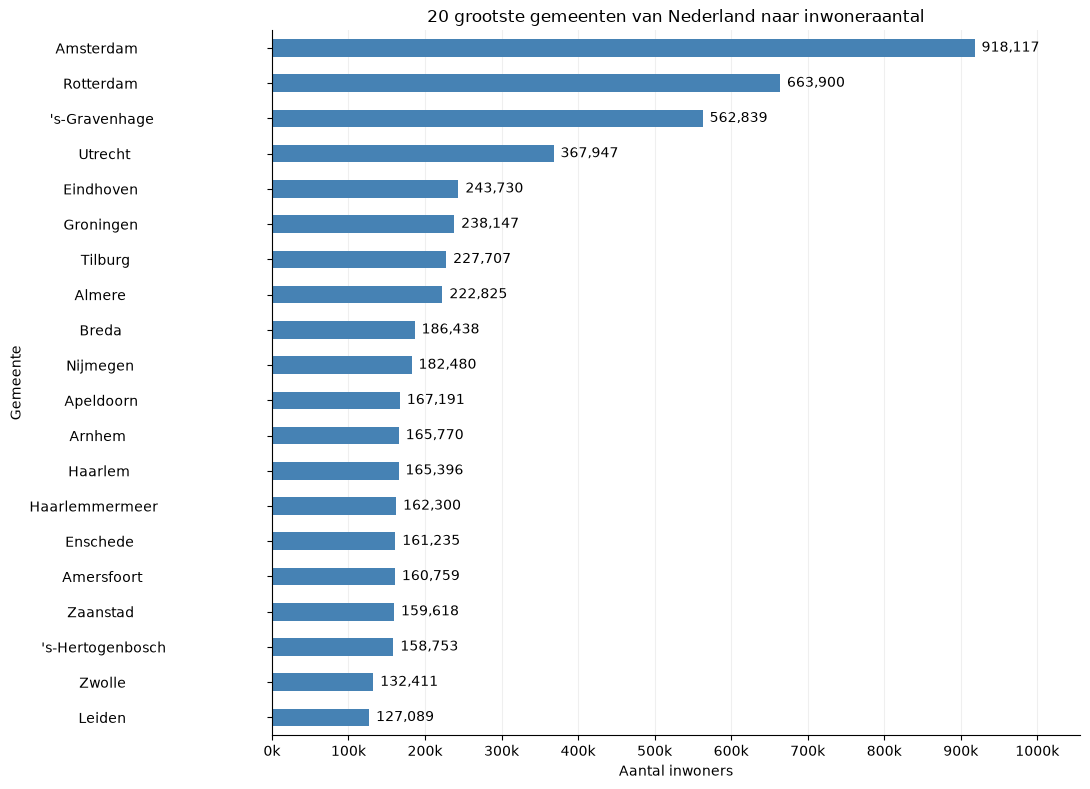

In [ ]:
import matplotlib.pyplot as plt
gemeenten = df[df['SoortRegio_2'].str.strip() == 'Gemeente']

df3 = gemeenten.groupby('Gemeentenaam_1')['AantalInwoners_5'].first()

print(df3.count())

import matplotlib.ticker as ticker

top20 = df3.nlargest(20).sort_values()

ax = top20.plot(
    kind='barh',
    figsize=(11, 8),
    color='steelblue'
)

# Getallen achter de staven
ax.bar_label(ax.containers[0], padding=5, fmt='{:,}')

# X-as in duizendtallen
ax.xaxis.set_major_locator(ticker.MultipleLocator(100000))
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x/1000:.0f}k')
)

# Bovenste en rechter rand verwijderen
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Rasterlijnen
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)

plt.title('20 grootste gemeenten van Nederland naar inwoneraantal')
plt.xlabel('Aantal inwoners')
plt.ylabel('Gemeente')
plt.xlim(0, top20.max() * 1.15)

plt.tight_layout()
plt.show()

#Uit de grafiek blijkt dat er grote verschillen zijn tussen het aantal inwoners per gemeente. Dit zijn de 20 grootste gemeenten, en Leiden (de onderste) heeft nog steeds bijna 800k minder inwoners dan Amsterdam (de grootste). 
#Dit geeft aan dat de behoefte voor energie enorm kan verschillen per gemeente. Rotterdam bijvoorbeeld zou ook een grotere behoefte hebben dan bijvoorbeeld Zaandam.
#Hiernaast moet er rekening gehouden worden met andere factoren, zoals de type woningen.

## 4.13 Aantal inwoners per stedelijkheidscategorie

MateVanStedelijkheid_125
1.0    4649795
2.0    5288761
3.0    2895280
4.0    3751137
5.0    1226318
Name: AantalInwoners_5, dtype: int64
MateVanStedelijkheid_125
Zeer sterk stedelijk    4649795
Sterk stedelijk         5288761
Matig stedelijk         2895280
Weinig stedelijk        3751137
Niet stedelijk          1226318
Name: AantalInwoners_5, dtype: int64


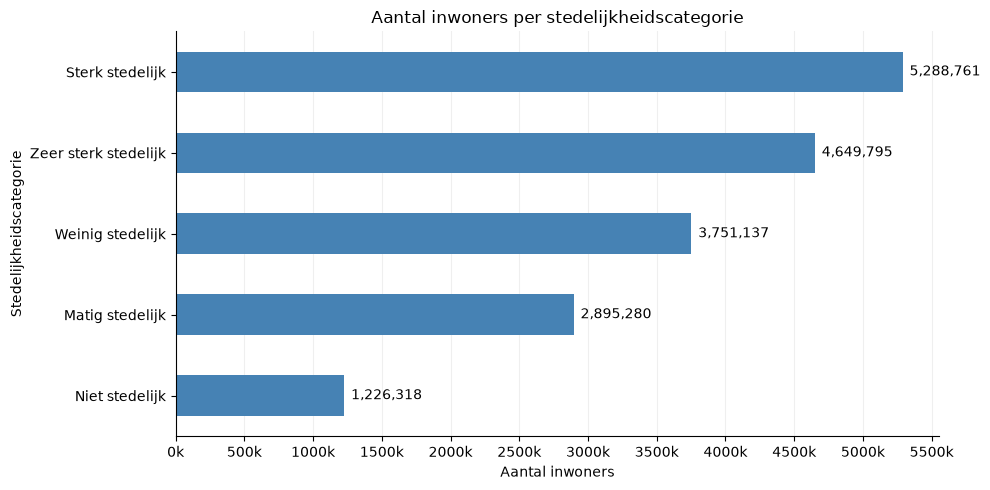

In [ ]:
gemeenten = df[df['SoortRegio_2'].str.strip() == 'Gemeente']

df_stedelijkheid = gemeenten.groupby('MateVanStedelijkheid_125')['AantalInwoners_5'].sum()

print(df_stedelijkheid)
#De vijf stedelijkheidscategorieën zijn:
#1. Zeer sterk stedelijk
#2. Sterk stedelijk
#3. Matig stedelijk
#4. Weinig stedelijk
#5. Niet stedelijk
df_stedelijkheid = gemeenten.groupby('MateVanStedelijkheid_125')['AantalInwoners_5'].sum()

df_stedelijkheid.index = df_stedelijkheid.index.map({
    1: 'Zeer sterk stedelijk',
    2: 'Sterk stedelijk',
    3: 'Matig stedelijk',
    4: 'Weinig stedelijk',
    5: 'Niet stedelijk'
})

print(df_stedelijkheid)

import matplotlib.ticker as ticker

ax = df_stedelijkheid.sort_values().plot(
    kind='barh',
    figsize=(10, 5),
    color='steelblue'
)

# Aantallen achter de staven
ax.bar_label(ax.containers[0], padding=5, fmt='{:,}')

# X-as in duizendtallen
ax.xaxis.set_major_locator(ticker.MultipleLocator(500000))
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x/1000:.0f}k')
)

# Bovenste en rechter rand verwijderen
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Rustige rasterlijnen
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)

plt.title('Aantal inwoners per stedelijkheidscategorie')
plt.xlabel('Aantal inwoners')
plt.ylabel('Stedelijkheidscategorie')

plt.tight_layout()
plt.show()

#In de grafiek kan je zien dat het aantal inwoners per stedelijkheidscategorie heel erg kunnen verschillen. Tussen sterk stedelijk en zeer sterk stedelijk zit al een verschil van bijna 650k inwoners. 
#Dit zou bijvoorbeeld kunnen omdat in sterk stedelijke gebieden mensen dicht bij elkaar wonen, en in niet stedelijk juist veel verder uit elkaar. Hier moet weer rekening mee worden gehouden met de elektriciteit, omdat het in dichtbebouwde gebieden het lastiger kan zijn om ruimte te vinden voor bv de kabels. Ook kan er daardoor op 1 gebied veel elektriciteit nodig zijn.
#Om de elektriciteitsbehoefte te kunnen weten moet je dus rekening houden met meerdere factoren door elkaar heen.

## 4.14 Drie extra nuttige visualisaties

In deze opdracht maken we drie extra visualisaties om meer inzicht te krijgen in het energieverbruik van buurten.

We maken de volgende grafieken:

1. Het gemiddelde elektriciteitsverbruik per stedelijkheidscategorie.
2. De relatie tussen de gemiddelde huishoudgrootte en het elektriciteitsverbruik.
3. De verdeling van het elektriciteitsverbruik over de buurten.

Deze grafieken zijn nuttig omdat we hiermee verschillen tussen stedelijkheidscategorieën, mogelijke verbanden en de verdeling van het energieverbruik kunnen onderzoeken.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# We gebruiken het dataframe met alleen buurten
grafieken = buurten.copy()

# De benodigde kolommen omzetten naar getallen
grafieken["GemiddeldeElektriciteitsleveringTotaal_48"] = pd.to_numeric(
    grafieken["GemiddeldeElektriciteitsleveringTotaal_48"],
    errors="coerce"
)

grafieken["GemiddeldeHuishoudgrootte_33"] = pd.to_numeric(
    grafieken["GemiddeldeHuishoudgrootte_33"],
    errors="coerce"
)

grafieken["MateVanStedelijkheid_125"] = pd.to_numeric(
    grafieken["MateVanStedelijkheid_125"],
    errors="coerce"
)

# Alleen rijen gebruiken waarin alle benodigde gegevens aanwezig zijn
grafieken = grafieken.dropna(
    subset=[
        "GemiddeldeElektriciteitsleveringTotaal_48",
        "GemiddeldeHuishoudgrootte_33",
        "MateVanStedelijkheid_125"
    ]
)

# Grafiek 1: gemiddeld elektriciteitsverbruik per stedelijkheidscategorie
verbruik_per_stedelijkheid = (
    grafieken
    .groupby("MateVanStedelijkheid_125")
    ["GemiddeldeElektriciteitsleveringTotaal_48"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=verbruik_per_stedelijkheid,
    x="MateVanStedelijkheid_125",
    y="GemiddeldeElektriciteitsleveringTotaal_48"
)

plt.title("Gemiddeld elektriciteitsverbruik per stedelijkheidscategorie")
plt.xlabel("Stedelijkheidscategorie")
plt.ylabel("Gemiddeld elektriciteitsverbruik")
plt.tight_layout()
plt.show()


# Grafiek 2: huishoudgrootte en elektriciteitsverbruik
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=grafieken,
    x="GemiddeldeHuishoudgrootte_33", 
    y="GemiddeldeElektriciteitsleveringTotaal_48",
    alpha=0.5
)

plt.title("Relatie tussen huishoudgrootte en elektriciteitsverbruik")
plt.xlabel("Gemiddelde huishoudgrootte")
plt.ylabel("Gemiddeld elektriciteitsverbruik")
plt.tight_layout()
plt.show()


# Grafiek 3: verdeling van het elektriciteitsverbruik
plt.figure(figsize=(8, 5))

sns.histplot(
    data=grafieken,
    x="GemiddeldeElektriciteitsleveringTotaal_48",
    bins=30,
    kde=True
)

plt.title("Verdeling van het elektriciteitsverbruik")
plt.xlabel("Gemiddeld elektriciteitsverbruik")
plt.ylabel("Aantal buurten")
plt.tight_layout()
plt.show()

KeyError: 'GemiddeldeHuishoudgrootte_33'

### Interpretatie van de visualisaties

De eerste grafiek laat zien of het gemiddelde elektriciteitsverbruik verschilt tussen de stedelijkheidscategorieën. Hierdoor kunnen we onderzoeken of stedelijkheid mogelijk samenhangt met energieverbruik.

De tweede grafiek toont de relatie tussen de gemiddelde huishoudgrootte en het elektriciteitsverbruik. Wanneer de punten van linksonder naar rechtsboven lopen, kan er sprake zijn van een positief verband. Dit betekent dat buurten met grotere huishoudens mogelijk meer elektriciteit verbruiken. Wanneer de punten sterk verspreid zijn, is het verband waarschijnlijk zwak.

De derde grafiek laat zien hoe het elektriciteitsverbruik over de buurten verdeeld is. Hiermee kunnen we zien waar de meeste buurten zich bevinden en of er sprake is van uitschieters of een scheve verdeling.

Deze drie grafieken zijn nuttig omdat ze elk een ander onderdeel van de dataset laten zien: verschillen tussen categorieën, een mogelijk verband tussen twee variabelen en de verdeling van het elektriciteitsverbruik.

# Opvallende resultaten samevatten



### Opvallende patronen 

Het gemiddelde elektriciteitsverbruik in de onderzochte buurten bedraagt 3002.02 kWh per huishouden, bij een gemiddeld huishouden van 2.27 persoon.

De verdeling over stedelijkheidscategorieën laat zien dat de meeste inwoners in categorie 2 (4.49 miljoen) en categorie 1 (4.43 miljoen) wonen, terwijl categorieën 4 en 5 duidelijk minder inwoners tellen (beide rond de 2.81 miljoen)


### Belangrijke relaties met elektriciteitverbruik 

Positieve verbanden
Buurten met veel eigen/koop woningen (correlatie EigenWoning_55: r = 0.95, Koopwoningen_41: r = 0.70) meer personenauto’s per huishouden (r = 0.74) een hoger mediaan vermogen (r = 0.73) en ook meer hogen inkomens (r = 0.72) hebben gemiddeld gezien een aanzienlijk hoger stroomverbruik. Ook het gasverbruik en de mate van stedelijkheid (r = 0.66) laten een sterk positief verband zien. 

Negatieve verbanden 
Buurten met een hoog aantal huurwoningen (HuurwoningenTotaal_42 : r = - 0.69) en sociale huur 
(InBezitWoningcorporatie_43: r = - 0.66) laten een duidelijk lager elektriciteit verbruik zien. 


### Afwijkingen en aandacht punten 
In de kolom MateVanStedelijkheid_125 zitten 84 ontbrekende waarde (NaN) en de categorieën staan nu nog als cijfers van (1.0 t/m 5.0) in plaats van categorische teksten.
Opvallen is dat Huurwoning_54 een hoge positieve correlatie (r = 0.83) toont, dat wijkt sterk af van HuurwoningenTotaal_42 met een negatieve correlatie van (r = -0.69) Dit wijst op een verschil tussen de absolute aantallen en percentages in de CBS-dataset.  Waarbij wij bij verdere analyse rekening gehouden mee moet worden, om tegenstrijdige conclusies te voorkomen. 


### AANVULLEN ZODRA 4.8 4.10 KLAAR ZIJN (Kyra)

# Conclusie over het voorspellen van energieverbruik
### Voorlopig antwoord op de hoofdvraag van het DataLab: hoe kan je het beste energieverbruik voorspellen


Meest bruikbare variabelen: Het gemiddelde elektriciteitsverbruik per huishouden is het beste te voorspellen op de basis van woningtype/eigendom (koopwoningen tegen over huur-/ corporatiewoningen), welvaartsindicatoren (mediaan en percentage hoge inkomens) en huishoudkenmerken zoals (aantal personenauto’s er huishouden en de mate van stedelijkheid)

Patronen die helpen bij voorspellingen: Koopwoningen, hogere inkomens en vermogen en minder stedelijke buurten gaan samen met grotere woningen en huishoudens, dit alles leidt tot een systematisch hoger energieverbruik.
Huur-/ corporatiewoningen voorspellen juist een lager verbruik. Daarnaast hangt het gasverbruik (r = 0.68) sterk samen met stroomverbruik, waardoor het ene energieverbruik ook een goede indicator is voor het andere. 



### Beperkingen van de analyses: 

1.	Correlatie is geen oorzaak of gevolg: Een hoog aantal auto’s veroorzaakt niet direct een hoger stroomverbruik beide zijn het gevolg van een onderliggende factor (zoals inkomen en woninggrote) 
2.	Overlapping tussen variabelen (dubbeltelling): veel kenmerken hangen onderling ook sterk samen, zoals een hoog inkomen en vermogen (r=0.81) of koop- en huurwoningen (r = - 1.00). Omdat ze eigenlijk dezelfde informatie geven, daarom moeten deze niet allemaal tegelijk in een voorspelmodel gebruiken 
3.	Deel uitkomsten uitsluiten: Variabelen zoals eigenwoning_55 (r=0.95) en huurwoning_54 (r=0.83) meten al het verbruik binnen een specifiek woningtype. Die moeten we buiten het model houden, omdat het ander het stroomverbruik voorspelt met gegevens die al een deel van de voorspelling/antwoorden bevatten. 
4.	Buurtgemiddelden en missende Data: De cijfers zijn gemiddelden per buurt (geen individuele huishoudens) en sommige kolommen bevatten missende waarde (84 NaN’s bij stedelijkheid). 



## 1. Benodigde bibliotheken

De onderstaande bestaande cel installeert de bibliotheek `cbsodata`. Voer de installatie alleen uit als dat in de gebruikte omgeving nodig is.

In [22]:
!python -m pip install cbsodata


## 2. Dataset importeren

Met de CBS API wordt tabel `85618NED` opgehaald en omgezet naar een pandas-dataframe (`df`). De eerste selectie op `SoortRegio_2` maakt een dataframe met buurten. De omvang van de volledige dataset wordt weergegeven met `df.shape`.

In [23]:
import cbsodata
import pandas as pd

# Gebruik een CBS-tabelcode (bijv. '83765ned' voor bevolkingsdata)
tabelcode = '85618NED'

# Haal de data direct op
data = cbsodata.get_data(tabelcode)
# Laad de data in een DataFrame
df = pd.DataFrame(data)

# Toon de eerste 5 rijen

buurten = df[df['SoortRegio_2'] == 'Buurt     ']
# door te filteren op de buurten, kunnen we de data beter analyseren en visualiseren, omdat buurten vaak specifieke kenmerken hebben die relevant zijn voor energiebedrijven om de energiebehoefte en -consumptie in kaart te brengen. Door te focussen op buurten kunnen we gerichte inzichten verkrijgen die kunnen helpen bij het optimaliseren van energievoorziening en -beleid.
df.shape


(18116, 128)

## 3. Eerste verkenning van de gegevens

We onderzoeken eerst welke regio-indelingen in de oorspronkelijke dataset voorkomen. Dit helpt om te controleren dat de latere analyses op één geografisch niveau worden uitgevoerd.

In [24]:
df['SoortRegio_2'].unique() 

<ArrowStringArray>
['Land      ', 'Gemeente  ', 'Wijk      ', 'Buurt     ']
Length: 4, dtype: str

### 3.1 Ontbrekende waarden en datatypes

De bestaande code toont per kolom het aantal ontbrekende waarden en het datatype. Controleer bij de interpretatie of ontbrekende waarden voor de analyse relevante variabelen treffen. De comments in de code zijn voorlopige observaties en moeten overeenkomen met de daadwerkelijke uitvoer.

In [25]:
print(buurten.isna().sum())
print(buurten.dtypes)

#5 rijen en 128 kolommen
#types zijn float64, int64 en str, dtype is object
#missende waarden zijn bij dekkingspercentage_124; 96, matevanstedelijkheid_125; 84 en omgevingsadressendichtheid_126; 84
#de eenheden die in deze dataset zijn gebruikt zijn: aantal, per 1000 inwoners, aantal inwoners per km2, euro's, percentages, kWh, m3, km2, km, ha, code


ID                                 0
WijkenEnBuurten                    0
Gemeentenaam_1                     0
SoortRegio_2                       0
Codering_3                         0
                                  ..
OppervlakteWater_122               0
MeestVoorkomendePostcode_123       0
Dekkingspercentage_124            96
MateVanStedelijkheid_125          84
Omgevingsadressendichtheid_126    84
Length: 128, dtype: int64
ID                                  int64
WijkenEnBuurten                       str
Gemeentenaam_1                        str
SoortRegio_2                          str
Codering_3                            str
                                   ...   
OppervlakteWater_122                int64
MeestVoorkomendePostcode_123          str
Dekkingspercentage_124            float64
MateVanStedelijkheid_125          float64
Omgevingsadressendichtheid_126    float64
Length: 128, dtype: object


### 3.2 Datasetbeschrijving en eerste statistieken

Met `describe()` bekijken we de numerieke verdelingen en met de volledige dataframeweergave de aanwezige kolommen. Voor het rubricniveau **Uitstekend** is daarnaast een controleerbaar overzicht per kolom nodig met betekenis, datatype, eenheid en ontbrekende waarden. De onderstaande code levert nog niet automatisch dat volledige overzicht.

In [26]:
display(buurten.describe())
display(buurten.iloc[:,:])
#bescrijvingen per kolom:
#Bevolking: aantal inwoners, geslachten, leeftijdsgroepen, allochtonen (autochtoon, niet-westerse, westerse).
#Wonen: aantal woningen, koop/huurverhouding, WOZ-waarde, leegstand, sociale huurwoningen, huishoudensgrootte.
#Inkomen: gemiddeld en mediaan inkomen, lage-inkomenshuishoudens, bijstandsontvangers, AOW-ontvangers.
#Energie: gas- en elektriciteitsverbruik, zonnepanelen, energiearmoedehuishoudens.
#Vervoer: aantal motorvoertuigen en personenauto’s, elektrische auto’s, openbaar vervoergebruik, parkeerplaatsen.
#Veiligheid: misdrijven (totaal en per 1.000 inwoners), woninginbraken, verkeersongevallen.
#Onderwijs: aantal basisschool- en middelbare scholieren, hoogopgeleiden (HBO/WO).
#Bedrijven: aantal bedrijven, banen (voltijdsequivalenten), startende bedrijven, faillissementen.
#Milieu: groenoppervlak, stedelijkheid, oppervlakte buurt.
#Voorzieningen: afstand tot basisschool, middelbare school en kinderdagverblijf, aantal scholen en kinderopvanglocaties in de buurt.
#Identificatie: buurtcode, buurtnaam, wijkcode, wijknaam, gemeentecode, gemeentenaam, provincie.

,ID,AantalInwoners_5,Mannen_6,Vrouwen_7,k_0Tot15Jaar_8,k_15Tot25Jaar_9,k_25Tot45Jaar_10,k_45Tot65Jaar_11,k_65JaarOfOuder_12,Ongehuwd_13,...,AfstandTotGroteSupermarkt_116,AfstandTotKinderdagverblijf_117,AfstandTotSchool_118,ScholenBinnen3Km_119,OppervlakteTotaal_120,OppervlakteLand_121,OppervlakteWater_122,Dekkingspercentage_124,MateVanStedelijkheid_125,Omgevingsadressendichtheid_126
count,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,...,13668.000000,13668.000000,13668.000000,13668.000000,14421.000000,14421.000000,14421.000000,14325.000000,14337.000000,14337.000000
mean,9017.870883,1235.024270,613.673809,621.348728,189.147077,151.883711,312.513695,331.758200,249.710145,613.746273,...,1.593437,1.141308,1.195910,6.742706,243.259899,233.318078,9.928715,1.255079,3.553812,1224.455814
std,5236.883157,1609.106229,793.833311,816.858689,267.708033,223.740814,465.505961,418.982896,336.571257,873.336365,...,1.374546,0.983929,0.951566,6.584308,537.572591,519.699332,52.688322,0.836123,1.479556,1510.914445
min,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.100000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,4447.000000,185.000000,95.000000,90.000000,25.000000,20.000000,35.000000,55.000000,35.000000,80.000000,...,0.600000,0.500000,0.500000,2.000000,25.000000,24.000000,0.000000,1.000000,2.000000,175.000000
50%,9011.000000,710.000000,360.000000,355.000000,95.000000,80.000000,155.000000,200.000000,135.000000,325.000000,...,1.100000,0.800000,0.800000,5.000000,55.000000,53.000000,1.000000,1.000000,4.000000,767.000000
75%,13550.000000,1695.000000,840.000000,855.000000,255.000000,195.000000,415.000000,455.000000,340.000000,815.000000,...,2.200000,1.600000,1.600000,9.500000,191.000000,178.000000,4.000000,1.000000,5.000000,1731.000000
max,18115.000000,29265.000000,14025.000000,15240.000000,5095.000000,3905.000000,8670.000000,6870.000000,7870.000000,15565.000000,...,14.000000,13.100000,13.200000,55.300000,13016.000000,12816.000000,2296.000000,6.000000,5.000000,12559.000000


,ID,WijkenEnBuurten,Gemeentenaam_1,SoortRegio_2,Codering_3,IndelingswijzigingGemeenteWijkBuurt_4,AantalInwoners_5,Mannen_6,Vrouwen_7,k_0Tot15Jaar_8,...,AfstandTotKinderdagverblijf_117,AfstandTotSchool_118,ScholenBinnen3Km_119,OppervlakteTotaal_120,OppervlakteLand_121,OppervlakteWater_122,MeestVoorkomendePostcode_123,Dekkingspercentage_124,MateVanStedelijkheid_125,Omgevingsadressendichtheid_126
3,3,Annen,Aa en Hunze,Buurt,BU16800000,1,3450,1680,1775,495,...,0.5,0.8,2.5,252,252,0,9468,1.0,5.0,410.0
4,4,Verspreide huizen Annen,Aa en Hunze,Buurt,BU16800009,1,150,75,80,15,...,1.8,2.0,1.2,1226,1213,13,9468,1.0,5.0,59.0
6,6,Eext,Aa en Hunze,Buurt,BU16800100,1,1270,655,620,185,...,1.2,0.9,1.0,171,170,1,9463,1.0,5.0,147.0
7,7,Verspreide huizen Eext,Aa en Hunze,Buurt,BU16800109,1,180,90,90,10,...,2.0,2.1,1.3,1618,1614,4,9463,1.0,5.0,37.0
9,9,Anloo,Aa en Hunze,Buurt,BU16800200,1,325,165,160,45,...,2.5,0.5,2.0,57,57,0,9467,1.0,5.0,95.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18110,18110,Gerenlanden,Zwolle,Buurt,BU01935140,1,3025,1480,1540,535,...,0.5,0.5,12.0,58,55,2,8014,1.0,2.0,1958.0
18111,18111,Gerenbroek,Zwolle,Buurt,BU01935150,1,3040,1520,1515,550,...,0.5,0.5,11.7,49,47,2,8014,1.0,2.0,1613.0
18112,18112,Oude Mars,Zwolle,Buurt,BU01935160,1,200,105,95,45,...,1.8,1.8,7.5,45,43,2,8015,1.0,4.0,759.0
18114,18114,Windesheim,Zwolle,Buurt,BU01935200,1,410,200,205,85,...,0.3,0.3,1.0,53,53,0,8015,1.0,5.0,62.0


---
## 4. Consistente granulariteit: buurten

De dataset kan verschillende geografische niveaus bevatten. Door uitsluitend buurten te selecteren voorkomen we dat gegevens van gemeenten en buurten in dezelfde vergelijking worden behandeld. Dit is belangrijk omdat gemeenten buurten omvatten en anders dubbeltellingen of misleidende vergelijkingen kunnen ontstaan.


## Data opschonen

### 1. Dataset inspecteren


We filteren op alleen buurten zodat alle rijen op hetzelfde niveau zitten en we geen buurten met hele gemeenten optellen of vergelijken.

In [27]:
# Dataframe buurten maken
buurten = df[df['SoortRegio_2'].str.strip() == 'Buurt']

In [28]:
buurten.info()

<class 'pandas.DataFrame'>
Index: 14421 entries, 3 to 18115
Columns: 128 entries, ID to Omgevingsadressendichtheid_126
dtypes: float64(79), int64(43), str(6)
memory usage: 15.4 MB


### 4.1 Keuzes bij het opschonen

De bestaande werkwijze verwijdert kolommen wanneer meer dan 30% van de waarden ontbreekt. Dat is een gekozen kwaliteitsdrempel, **geen algemeen bewezen standaard**. Voor een beoordeling op *Uitstekend* moet deze keuze nog worden onderbouwd met een passende bron of een analyse van de gevolgen van verschillende drempels.

Daarnaast worden drie administratieve kolommen verwijderd. Controleer dat de kolommen die nodig zijn voor identificatie, koppeling en toekomstige energieanalyses behouden blijven.

### Waarom buurten filteren en data opschonen?
- **Alleen buurten:** We vergelijken alleen buurten met elkaar en geen gemeenten of landsdelen, zodat alle rijen op hetzelfde niveau liggen (consistente granulariteit).
- **Drempelwaarde lege vakjes (30%):** Als meer dan 30% van de gegevens ontbreekt, vinden wij de kolom te onbetrouwbaar om mee te rekenen.
- **Relevante kolommen:** Kenmerken zoals woningtype (bijv. tussenwoning, appartement, vrijstaand) en huishoudensgrootte houden we, omdat die direct invloed hebben op stroomverbruik.
- **Niet-relevante kolommen:** Administratieve kolommen zoals 'ID', 'Codering_3' en 'SoortRegio_2' hebben geen voorspellende waarde en worden verwijderd.

### 4.2 Opschoning uitvoeren en controleren

De code maakt `buurten_schoon` en vergelijkt het aantal rijen en kolommen vóór en na de opschoning. Noteer op basis van de uitvoer hoeveel kolommen daadwerkelijk zijn verwijderd en of het aantal buurten gelijk is gebleven.

In [29]:
# 1. Kolommen met meer dan 30% ontbrekende waarden verwijderen
grens = 0.70 * len(buurten)
buurten_schoon = buurten.dropna(thresh=grens, axis=1)

# 2. Niet-relevante kolommen verwijderen
nutteloos = ['ID', 'Codering_3', 'SoortRegio_2']
buurten_schoon = buurten_schoon.drop(columns=[col for col in nutteloos if col in buurten_schoon.columns])

# 3. Eindresultaat controleren
print("Voor opschonen:", buurten.shape)
print("Na opschonen:", buurten_schoon.shape)

Voor opschonen: (14421, 128)
Na opschonen: (14421, 106)


---
## 5. Basisstatistieken

In dit onderdeel worden de basisstatistieken, gemeentetotalen en percentages berekend met de bestaande codecellen.


### 5.1 Beschrijvende basisstatistieken

#### Basisstatistieken

**Basisstatistieken berekenen**

Om de dataset verder te verkennen, berekenen we de basisstatistieken van alle numerieke kolommen uit het opgeschoonde dataframe buurten_schoon.

Per numerieke kolom berekenen we:

**Minimum:** De laagste waarde.

**Maximum:** De hoogste waarde.

**Gemiddelde:** De som van alle waarden gedeeld door het aantal beschikbare waarden.

**Mediaan:** De middelste waarde wanneer alle waarden van laag naar hoog worden gesorteerd.

Ontbrekende waarden worden automatisch buiten de berekeningen gehouden. De resultaten worden weergegeven in een Markdown-tabel, zodat de verschillende variabelen overzichtelijk vergeleken kunnen worden.

In [30]:
# Basisstatistieken:

## Dean
# Minimum: De laagste waarde.
# Maximum: De hoogste waarde.
# Gemiddelde: De som van alle waarden gedeeld door het aantal beschikbare waarden.
# Mediaan: De middelste waarde wanneer alle waarden van laag naar hoog worden gesorteerd.

# Basisstatistieken berekenen voor alle numerieke kolommen

# Controleer eerst of de opgeschoonde dataset beschikbaar is.
# Deze variabele wordt aangemaakt in de cel "Kolommen opschonen" hierboven.
if "buurten_schoon" not in globals():
    raise RuntimeError(
        "De dataset 'buurten_schoon' bestaat nog niet. Voer eerst de eerdere cellen uit, "
        "met name de cel waarin 'buurten_schoon' wordt aangemaakt. "
        "Kies eventueel Kernel > Restart Kernel and Run All Cells."
    )

# Selecteer alle numerieke kolommen uit de opgeschoonde dataset
numerieke_kolommen = buurten_schoon.select_dtypes(include="number").columns

if len(numerieke_kolommen) == 0:
    raise ValueError("Er zijn geen numerieke kolommen gevonden in 'buurten_schoon'.")

# Bereken minimum, maximum, gemiddelde en mediaan per numerieke kolom
basisstatistieken = buurten_schoon[numerieke_kolommen].agg(
    ["min", "max", "mean", "median"]
).T

# Geef de statistieken Nederlandse kolomnamen en rond af op twee decimalen
basisstatistieken = basisstatistieken.rename(columns={
    "min": "Minimum",
    "max": "Maximum",
    "mean": "Gemiddelde",
    "median": "Mediaan"
}).round(2)

# Maak zelf een Markdown-tabel. Hiervoor is de extra package 'tabulate' niet nodig.
def dataframe_naar_markdown(dataframe):
    tabel = dataframe.copy()
    tabel.insert(0, "Numerieke kolom", tabel.index.astype(str))

    def formatteer_waarde(waarde):
        if pd.isna(waarde):
            return "—"
        return str(waarde).replace("|", r"\|").replace("\n", " ")

    kop = "| " + " | ".join(formatteer_waarde(kolom) for kolom in tabel.columns) + " |"
    scheiding = "| " + " | ".join("---" for _ in tabel.columns) + " |"
    rijen = [
        "| " + " | ".join(formatteer_waarde(waarde) for waarde in rij) + " |"
        for rij in tabel.itertuples(index=False, name=None)
    ]
    return "\n".join([kop, scheiding] + rijen)

from IPython.display import display, Markdown

display(Markdown(dataframe_naar_markdown(basisstatistieken)))

| Numerieke kolom | Minimum | Maximum | Gemiddelde | Mediaan |
| --- | --- | --- | --- | --- |
| AantalInwoners_5 | 0.0 | 29265.0 | 1235.02 | 710.0 |
| Mannen_6 | 0.0 | 14025.0 | 613.67 | 360.0 |
| Vrouwen_7 | 0.0 | 15240.0 | 621.35 | 355.0 |
| k_0Tot15Jaar_8 | 0.0 | 5095.0 | 189.15 | 95.0 |
| k_15Tot25Jaar_9 | 0.0 | 3905.0 | 151.88 | 80.0 |
| k_25Tot45Jaar_10 | 0.0 | 8670.0 | 312.51 | 155.0 |
| k_45Tot65Jaar_11 | 0.0 | 6870.0 | 331.76 | 200.0 |
| k_65JaarOfOuder_12 | 0.0 | 7870.0 | 249.71 | 135.0 |
| Ongehuwd_13 | 0.0 | 15565.0 | 613.75 | 325.0 |
| Gehuwd_14 | 0.0 | 9200.0 | 465.24 | 280.0 |
| Gescheiden_15 | 0.0 | 3100.0 | 96.19 | 45.0 |
| Verweduwd_16 | 0.0 | 2075.0 | 59.89 | 25.0 |
| Nederland_17 | 0.0 | 16390.0 | 899.94 | 550.0 |
| EuropaExclusiefNederland_18 | 0.0 | 4365.0 | 112.11 | 45.0 |
| BuitenEuropa_19 | 0.0 | 12980.0 | 222.97 | 45.0 |
| Nederland_20 | 0.0 | 16390.0 | 899.91 | 550.0 |
| EuropaExclusiefNederland_21 | 0.0 | 1060.0 | 41.95 | 20.0 |
| BuitenEuropa_22 | 0.0 | 6310.0 | 100.63 | 20.0 |
| EuropaExclusiefNederland_23 | 0.0 | 3790.0 | 70.17 | 20.0 |
| BuitenEuropa_24 | 0.0 | 6670.0 | 122.33 | 25.0 |
| GeboorteTotaal_25 | 0.0 | 320.0 | 11.38 | 5.0 |
| GeboorteRelatief_26 | 0.0 | 235.0 | 7.96 | 8.0 |
| SterfteTotaal_27 | 0.0 | 455.0 | 11.77 | 5.0 |
| SterfteRelatief_28 | 0.0 | 551.0 | 8.95 | 6.0 |
| HuishoudensTotaal_29 | 0.0 | 14180.0 | 573.39 | 310.0 |
| Eenpersoonshuishoudens_30 | 0.0 | 7485.0 | 226.42 | 90.0 |
| HuishoudensZonderKinderen_31 | 0.0 | 3265.0 | 163.59 | 95.0 |
| HuishoudensMetKinderen_32 | 0.0 | 4650.0 | 183.43 | 100.0 |
| GemiddeldeHuishoudensgrootte_33 | 1.0 | 6.0 | 2.27 | 2.3 |
| Bevolkingsdichtheid_34 | 0.0 | 55375.0 | 3239.39 | 2001.0 |
| Woningvoorraad_35 | 0.0 | 14277.0 | 563.43 | 305.0 |
| GemiddeldeWOZWaardeVanWoningen_36 | 34.0 | 2236.0 | 415.88 | 388.0 |
| PercentageEengezinswoning_37 | 0.0 | 100.0 | 76.21 | 87.0 |
| PercentageMeergezinswoning_38 | 0.0 | 100.0 | 23.79 | 13.0 |
| PercentageBewoond_39 | 0.0 | 100.0 | 94.53 | 96.0 |
| PercentageOnbewoond_40 | 0.0 | 100.0 | 5.47 | 4.0 |
| Koopwoningen_41 | 0.0 | 100.0 | 68.09 | 74.0 |
| HuurwoningenTotaal_42 | 0.0 | 100.0 | 31.77 | 26.0 |
| InBezitWoningcorporatie_43 | 0.0 | 100.0 | 18.33 | 13.0 |
| InBezitOverigeVerhuurders_44 | 0.0 | 100.0 | 13.44 | 9.0 |
| EigendomOnbekend_45 | 0.0 | 33.0 | 0.13 | 0.0 |
| BouwjaarVoor2000_46 | 0.0 | 100.0 | 80.35 | 88.0 |
| BouwjaarVanaf2000_47 | 0.0 | 100.0 | 19.65 | 12.0 |
| GemiddeldeElektriciteitsleveringTotaal_48 | 890.0 | 8310.0 | 3002.02 | 2830.0 |
| VrijstaandeWoning_53 | 1560.0 | 8310.0 | 3932.02 | 3900.0 |
| Huurwoning_54 | 790.0 | 6380.0 | 2347.54 | 2080.0 |
| EigenWoning_55 | 1380.0 | 8310.0 | 3239.11 | 3090.0 |
| GemiddeldAardgasverbruikTotaal_56 | 0.0 | 3540.0 | 1007.5 | 990.0 |
| VrijstaandeWoning_61 | 0.0 | 4010.0 | 1363.63 | 1350.0 |
| Huurwoning_62 | 0.0 | 2760.0 | 875.38 | 800.0 |
| EigenWoning_63 | 0.0 | 3530.0 | 1061.61 | 1060.0 |
| LeerlingenPo_65 | 0.0 | 2810.0 | 101.58 | 50.0 |
| LeerlingenVoInclVavo_66 | 0.0 | 1490.0 | 66.08 | 40.0 |
| StudentenMboExclExtranei_67 | 0.0 | 1100.0 | 32.62 | 20.0 |
| StudentenHbo_68 | 0.0 | 1240.0 | 31.29 | 10.0 |
| StudentenWo_69 | 0.0 | 2280.0 | 22.32 | 0.0 |
| WerkzameBeroepsbevolking_73 | 0.0 | 13290.0 | 662.03 | 380.0 |
| Nettoarbeidsparticipatie_74 | 14.0 | 95.0 | 72.71 | 73.0 |
| AantalInkomensontvangers_79 | 0.0 | 22500.0 | 996.45 | 600.0 |
| GemiddeldInkomenPerInkomensontvanger_80 | 7.8 | 151.3 | 40.55 | 39.0 |
| GemiddeldInkomenPerInwoner_81 | 7.4 | 108.0 | 33.73 | 32.7 |
| k_40PersonenMetLaagsteInkomen_82 | 8.0 | 93.3 | 39.42 | 39.0 |
| k_20PersonenMetHoogsteInkomen_83 | 0.0 | 65.7 | 20.69 | 19.8 |
| k_40HuishoudensMetLaagsteInkomen_85 | 0.9 | 100.0 | 35.64 | 33.1 |
| k_20HuishoudensMetHoogsteInkomen_86 | 0.0 | 79.8 | 23.14 | 21.3 |
| HuishoudensMetEenLaagInkomen_87 | 0.0 | 45.1 | 3.3 | 2.6 |
| HuishOnderOfRondSociaalMinimum_88 | 0.0 | 38.2 | 5.27 | 4.1 |
| HuishoudensTot110VanSociaalMinimum_89 | 0.0 | 58.7 | 7.94 | 6.2 |
| HuishoudensTot120VanSociaalMinimum_90 | 0.0 | 70.9 | 10.14 | 8.2 |
| MediaanVermogenVanParticuliereHuish_91 | -6.1 | 3016.0 | 234.09 | 207.6 |
| PersonenPerSoortUitkeringBijstand_92 | 0.0 | 1790.0 | 31.12 | 10.0 |
| PersonenPerSoortUitkeringAO_93 | 0.0 | 1470.0 | 59.87 | 30.0 |
| PersonenPerSoortUitkeringWW_94 | 0.0 | 280.0 | 11.03 | 10.0 |
| PersonenPerSoortUitkeringAOW_95 | 0.0 | 7220.0 | 253.03 | 150.0 |
| WmoClienten_98 | 10.0 | 3580.0 | 117.45 | 70.0 |
| WmoClientenRelatief_99 | 4.0 | 896.0 | 69.23 | 58.0 |
| BedrijfsvestigingenTotaal_100 | 0.0 | 5585.0 | 163.54 | 100.0 |
| ALandbouwBosbouwEnVisserij_101 | 0.0 | 385.0 | 5.88 | 0.0 |
| BFNijverheidEnEnergie_102 | 0.0 | 1285.0 | 26.73 | 15.0 |
| GIHandelEnHoreca_103 | 0.0 | 1055.0 | 31.24 | 15.0 |
| HJVervoerInformatieEnCommunicatie_104 | 0.0 | 610.0 | 14.23 | 5.0 |
| KLFinancieleDienstenOnroerendGoed_105 | 0.0 | 500.0 | 14.04 | 10.0 |
| MNZakelijkeDienstverlening_106 | 0.0 | 1965.0 | 43.19 | 25.0 |
| OQOverheidOnderwijsEnZorg_107 | 0.0 | 650.0 | 31.05 | 20.0 |
| RUCultuurRecreatieOverigeDiensten_108 | 0.0 | 535.0 | 20.38 | 10.0 |
| PersonenautoSTotaal_109 | 0.0 | 62120.0 | 593.91 | 370.0 |
| PersonenautoSBrandstofBenzine_110 | 0.0 | 33740.0 | 472.35 | 290.0 |
| PersonenautoSOverigeBrandstof_111 | 0.0 | 32750.0 | 121.55 | 75.0 |
| PersonenautoSPerHuishouden_112 | 0.0 | 2.5 | 1.17 | 1.2 |
| PersonenautoSNaarOppervlakte_113 | 0.0 | 14129.0 | 1603.56 | 1468.0 |
| Motorfietsen_114 | 0.0 | 605.0 | 47.75 | 30.0 |
| AfstandTotHuisartsenpraktijk_115 | 0.0 | 13.5 | 1.72 | 1.2 |
| AfstandTotGroteSupermarkt_116 | 0.0 | 14.0 | 1.59 | 1.1 |
| AfstandTotKinderdagverblijf_117 | 0.0 | 13.1 | 1.14 | 0.8 |
| AfstandTotSchool_118 | 0.1 | 13.2 | 1.2 | 0.8 |
| ScholenBinnen3Km_119 | 0.0 | 55.3 | 6.74 | 5.0 |
| OppervlakteTotaal_120 | 0.0 | 13016.0 | 243.26 | 55.0 |
| OppervlakteLand_121 | 0.0 | 12816.0 | 233.32 | 53.0 |
| OppervlakteWater_122 | 0.0 | 2296.0 | 9.93 | 1.0 |
| Dekkingspercentage_124 | 1.0 | 6.0 | 1.26 | 1.0 |
| MateVanStedelijkheid_125 | 1.0 | 5.0 | 3.55 | 4.0 |
| Omgevingsadressendichtheid_126 | 1.0 | 12559.0 | 1224.46 | 767.0 |


---
## 6. Vergelijking met officiële CBS-gemeentecijfers

De bestaande code telt inwonersaantallen per gemeente op uit de buurtgegevens en vergelijkt deze met gemeentecijfers uit de oorspronkelijke CBS-dataset. Het verschil wordt berekend als **eigen totaal minus CBS-totaal**.

**Interpretatie na uitvoering:** bespreek voor de getoonde gemeenten de grootte en richting van de verschillen. Afronding van buurtaantallen kan een verklaring zijn, maar mag niet zonder controle als enige oorzaak worden aangenomen.

###
Voor een selectie van gemeenten vergelijken we de opgesomde buurttotalen met de officiële gemeentecijfers van het CBS. Kleine verschillen ontstaan doordat het CBS buurtaantallen om privacyredenen afrondt op vijftallen; doordat deze afrondingen per afzonderlijke buurt worden opgeteld, cumuleert het afrondingsverschil vooral bij grotere gemeenten met veel buurten.

In [31]:
# Basisstatistieken:

##kyra
# Totalen per gemeente 
# geschikte kolommen voor totalen selecteren
# totalen per gemeente berekenen .groupby()
# aantal inwoners per gemeeente  

import pandas as pd
#meetwaarden data set obs=observations
df_obs= pd.read_csv("Observations.csv", sep=";" )
#gebiedscodes & namen 
df_regios= pd.read_csv("WijkenEnBuurtenCodes.csv", sep=";")
#rijen & kolom namen 
print("Observattions:")
display(df_obs.head(3))

print("regio codes:")
display(df_regios.head(3))

#gegevens koppelen per gemeente 
df_totaal= pd.merge(df_obs, df_regios, how="left", left_on= "WijkenEnBuurten", right_on="Identifier")
display(df_totaal.head(5))

# filteren enkel data gemeente GM  (geschikte kolommen voor totalen selecteren)
df_totaal ["Value"]= pd.to_numeric(df_totaal["Value"], errors="coerce")
# aantal inwoners per gemeeente  
df_gemeente_inwoners= df_totaal[(df_totaal["DimensionGroupId"]== "GM") & (df_totaal["Measure"]=="T001036" )]
#groepeer per gemeente  (totalen per gemeente berekenen .groupby())
totalen_per_gemeente= (df_gemeente_inwoners.groupby("Title")["Value"].sum().reset_index())
display(totalen_per_gemeente.head())

Observattions:


,Id,Measure,WijkenEnBuurten,Value,StringValue,ValueAttribute
0,0,GM000C,NL00,NaN,Nederland,NaN
1,1,R00003,NL00,NaN,Land,NaN
2,2,R00004,NL00,NaN,NL00,NaN


regio codes:


,Identifier,DimensionGroupId,DimensionId,Index,Title,Description,DetailRegionCode
0,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
1,GM1680,GM,WijkenEnBuurten,2,Aa en Hunze,Gemeente 'Aa en Hunze' (GM1680),GM1680
2,WK168000,GM1680,WijkenEnBuurten,3,Wijk 00 Annen,Wijk 'Wijk 00 Annen' (WK168000) is een wijk in...,WK168000


,Id,Measure,WijkenEnBuurten,Value,StringValue,ValueAttribute,Identifier,DimensionGroupId,DimensionId,Index,Title,Description,DetailRegionCode
0,0,GM000C,NL00,NaN,Nederland,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
1,1,R00003,NL00,NaN,Land,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
2,2,R00004,NL00,NaN,NL00,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
3,3,T001036,NL00,17811291,NaN,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
4,4,3000,NL00,8850309,NaN,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN


,Title,Value
0,'s-Gravenhage,562839.0
1,'s-Hertogenbosch,158753.0
2,Aa en Hunze,25724.0
3,Aalsmeer,33063.0
4,Aalten,27244.0



---
## 7. Demografische percentages op buurtniveau

De bestaande code berekent percentages voor tien demografische variabelen. De formule is `aantal in groep / totaal aantal inwoners × 100`. De laatste controle telt de percentages mannen en vrouwen bij elkaar op.

**Interpretatie na uitvoering:** controleer of de percentages plausibel zijn, of buurten met nul inwoners tot ontbrekende of oneindige waarden leiden en of afronding afwijkingen van 100% kan verklaren.

In [32]:

# 1. Eigen buurttotalen berekenen
buurten_schoon["AantalInwoners_5"] = pd.to_numeric(
    buurten_schoon["AantalInwoners_5"],
    errors="coerce"
)

eigen_totalen = (
    buurten_schoon
    .groupby("Gemeentenaam_1")["AantalInwoners_5"]
    .sum()
    .reset_index()
)

eigen_totalen.columns = ["Gemeente", "Eigen_Totaal"]
eigen_totalen["Gemeente"] = eigen_totalen["Gemeente"].astype(str).str.strip()


# 2. Officiele CBS-gemeentecijfers ophalen uit originele dataset
cbs_gemeenten = df[
    df["SoortRegio_2"].astype(str).str.strip() == "Gemeente"
].copy()

# Zorg ervoor dat inwonersaantallen numeriek zijn
cbs_gemeenten["AantalInwoners_5"] = pd.to_numeric(
    cbs_gemeenten["AantalInwoners_5"],
    errors="coerce"
)

# Alleen gemeentenaam en inwonersaantal behouden
cbs_totalen = cbs_gemeenten[
    ["Gemeentenaam_1", "AantalInwoners_5"]
].copy()

cbs_totalen.columns = ["Gemeente", "CBS_Totaal"]

cbs_totalen["Gemeente"] = (
    cbs_totalen["Gemeente"].astype(str).str.strip()
)


# 3. Eigen resultaten vergelijken met CBS
vergelijking = pd.merge(
    eigen_totalen,
    cbs_totalen,
    on="Gemeente",
    how="inner"
)

vergelijking["Verschil"] = (
    vergelijking["Eigen_Totaal"] - vergelijking["CBS_Totaal"]
)


# 4. Een selectie van gemeenten tonen
selectie = [
    "'s-Gravenhage",
    "Aa en Hunze",
    "Aalsmeer",
    "Almere"
]

vergelijking_selectie = vergelijking[
    vergelijking["Gemeente"].isin(selectie)
]

display(vergelijking_selectie)


,Gemeente,Eigen_Totaal,CBS_Totaal,Verschil
0,'s-Gravenhage,562490,562839,-349
2,Aa en Hunze,25700,25724,-24
3,Aalsmeer,33065,33063,2
10,Almere,222850,222825,25


## 8. Percentages per buurt berekenen

In deze stap berekenen we percentages van verschillende demografische groepen per buurt.

Hiervoor gebruiken we:
- het aantal inwoners als noemer
- de demografische aantallen als teller

Formule:

percentage = (aantal / totaal aantal inwoners) * 100

De percentages worden toegevoegd als nieuwe kolommen aan het dataframe.

In [33]:
# Selecteer demografische kolommen
demografische_kolommen = [
    'Mannen_6',
    'Vrouwen_7',
    'k_0Tot15Jaar_8',
    'k_15Tot25Jaar_9',
    'k_25Tot45Jaar_10',
    'k_45Tot65Jaar_11',
    'k_65JaarOfOuder_12',
    'Ongehuwd_13',
    'Gehuwd_14',
    'Gescheiden_15'
]

# Zorg dat de kolommen numeriek zijn
buurten_schoon['AantalInwoners_5'] = pd.to_numeric(
    buurten_schoon['AantalInwoners_5'],
    errors='coerce'
)

for col in demografische_kolommen:

    buurten_schoon[col] = pd.to_numeric(
        buurten_schoon[col],
        errors='coerce'
    )

    # Nieuwe percentagekolom maken
    perc_colnaam = f"Perc_{col}"

    buurten_schoon[perc_colnaam] = (
        buurten_schoon[col] /
        buurten_schoon['AantalInwoners_5']
    ) * 100

# Nieuwe percentagekolommen tonen
percentagekolommen = [
    f"Perc_{col}" for col in demografische_kolommen
]

display(
    buurten_schoon[
        ['Gemeentenaam_1', 'WijkenEnBuurten', 'AantalInwoners_5']
        + percentagekolommen
    ].head()
)

# Controleren of percentages logisch zijn
buurten_schoon['Totaal_Percentage'] = (
    buurten_schoon['Perc_Mannen_6'] +
    buurten_schoon['Perc_Vrouwen_7']
)

# Controle tonen
display(
    buurten_schoon[
        ['WijkenEnBuurten', 'Totaal_Percentage']
    ].head()
)

,Gemeentenaam_1,WijkenEnBuurten,AantalInwoners_5,Perc_Mannen_6,Perc_Vrouwen_7,Perc_k_0Tot15Jaar_8,Perc_k_15Tot25Jaar_9,Perc_k_25Tot45Jaar_10,Perc_k_45Tot65Jaar_11,Perc_k_65JaarOfOuder_12,Perc_Ongehuwd_13,Perc_Gehuwd_14,Perc_Gescheiden_15
3,Aa en Hunze,Annen,3450,48.695652,51.449275,14.347826,10.289855,17.826087,30.579710,27.101449,40.434783,45.942029,7.391304
4,Aa en Hunze,Verspreide huizen Annen,150,50.000000,53.333333,10.000000,10.000000,10.000000,43.333333,30.000000,33.333333,56.666667,3.333333
6,Aa en Hunze,Eext,1270,51.574803,48.818898,14.566929,11.023622,22.047244,30.708661,21.653543,44.488189,43.307087,7.480315
7,Aa en Hunze,Verspreide huizen Eext,180,50.000000,50.000000,5.555556,8.333333,19.444444,30.555556,36.111111,41.666667,47.222222,8.333333
9,Aa en Hunze,Anloo,325,50.769231,49.230769,13.846154,9.230769,16.923077,35.384615,26.153846,38.461538,49.230769,9.230769


,WijkenEnBuurten,Totaal_Percentage
3,Annen,100.144928
4,Verspreide huizen Annen,103.333333
6,Eext,100.393701
7,Verspreide huizen Eext,100.000000
9,Anloo,100.000000



## 9. Bronnen en verantwoording

- Centraal Bureau voor de Statistiek (CBS), StatLine-tabel `85618NED`.
- Documentatie van `cbsodata`.


## Sprint 4

### 4.1 Controle van de opgeschoonde dataset

We gebruiken `buurten_schoon` uit sprint 3. We controleren
het aantal buurten en kolommen en bekijken de eerste rijen.

In [34]:
print("Aantal buurten:", buurten_schoon.shape[0])
print("Aantal kolommen:", buurten_schoon.shape[1])

display(buurten_schoon.head())

Aantal buurten: 14421
Aantal kolommen: 117


,WijkenEnBuurten,Gemeentenaam_1,IndelingswijzigingGemeenteWijkBuurt_4,AantalInwoners_5,Mannen_6,Vrouwen_7,k_0Tot15Jaar_8,k_15Tot25Jaar_9,k_25Tot45Jaar_10,k_45Tot65Jaar_11,...,Perc_Vrouwen_7,Perc_k_0Tot15Jaar_8,Perc_k_15Tot25Jaar_9,Perc_k_25Tot45Jaar_10,Perc_k_45Tot65Jaar_11,Perc_k_65JaarOfOuder_12,Perc_Ongehuwd_13,Perc_Gehuwd_14,Perc_Gescheiden_15,Totaal_Percentage
3,Annen,Aa en Hunze,1,3450,1680,1775,495,355,615,1055,...,51.449275,14.347826,10.289855,17.826087,30.579710,27.101449,40.434783,45.942029,7.391304,100.144928
4,Verspreide huizen Annen,Aa en Hunze,1,150,75,80,15,15,15,65,...,53.333333,10.000000,10.000000,10.000000,43.333333,30.000000,33.333333,56.666667,3.333333,103.333333
6,Eext,Aa en Hunze,1,1270,655,620,185,140,280,390,...,48.818898,14.566929,11.023622,22.047244,30.708661,21.653543,44.488189,43.307087,7.480315,100.393701
7,Verspreide huizen Eext,Aa en Hunze,1,180,90,90,10,15,35,55,...,50.000000,5.555556,8.333333,19.444444,30.555556,36.111111,41.666667,47.222222,8.333333,100.000000
9,Anloo,Aa en Hunze,1,325,165,160,45,30,55,115,...,49.230769,13.846154,9.230769,16.923077,35.384615,26.153846,38.461538,49.230769,9.230769,100.000000


### 4.5 Correlatietabel maken

We onderzoeken welke numerieke buurtkenmerken samenhangen
met het gemiddelde elektriciteitsverbruik.

Een positieve correlatie betekent dat hogere waarden van
een kenmerk samengaan met hoger elektriciteitsverbruik.
Bij een negatieve correlatie gaan hogere waarden samen
met lager elektriciteitsverbruik.

Hoe dichter de correlatie bij -1 of +1 ligt, hoe sterker
het lineaire verband. Correlatie bewijst geen oorzaak.

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
# Elektriciteitsverbruik dat we willen voorspellen
doel = "GemiddeldeElektriciteitsleveringTotaal_48"

# Numerieke kolommen selecteren
numeriek = buurten_schoon.select_dtypes(include="number")

# Uitsplitsingen van elektriciteitsverbruik uitsluiten
uitsluiten = [
    kolom for kolom in numeriek.columns
    if kolom.endswith(("_49", "_50", "_51", "_52", "_53", "_54", "_55"))
]

# Codes, categorieën en controlekolommen uitsluiten
uitsluiten += [
    "IndelingswijzigingGemeenteWijkBuurt_4",
    "MeestVoorkomendePostcode_123",
    "Dekkingspercentage_124",
    "MateVanStedelijkheid_125",
    "Totaal_Percentage"
]

numeriek = numeriek.drop(columns=uitsluiten, errors="ignore")

# Oneindige waarden vervangen door ontbrekende waarden
numeriek = numeriek.replace(
    [float("inf"), float("-inf")], float("nan")
)

# Correlaties met elektriciteitsverbruik berekenen
correlaties = numeriek.corrwith(numeriek[doel])

# Correlatie met zichzelf verwijderen
correlaties = correlaties.drop(doel)

# Sorteren op absolute correlatiesterkte
volgorde = correlaties.abs().sort_values(ascending=False).index
correlaties = correlaties.loc[volgorde]

# Volledige tabel tonen
correlatietabel = correlaties.to_frame(name="Correlatie")
print(correlatietabel.round(3).to_string())

                                         Correlatie
PersonenautoSPerHuishouden_112                0.736
MediaanVermogenVanParticuliereHuish_91        0.726
k_20HuishoudensMetHoogsteInkomen_86           0.721
Koopwoningen_41                               0.695
HuurwoningenTotaal_42                        -0.694
GemiddeldAardgasverbruikTotaal_56             0.683
InBezitWoningcorporatie_43                   -0.665
Huurwoning_62                                 0.659
PersonenautoSNaarOppervlakte_113             -0.641
GemiddeldeHuishoudensgrootte_33               0.636
k_40HuishoudensMetLaagsteInkomen_85          -0.633
Bevolkingsdichtheid_34                       -0.628
PercentageEengezinswoning_37                  0.605
PercentageMeergezinswoning_38                -0.605
GemiddeldeWOZWaardeVanWoningen_36             0.603
EigenWoning_63                                0.590
Omgevingsadressendichtheid_126               -0.575
HuishoudensTot120VanSociaalMinimum_90        -0.561
HuishoudensT

### 4.6 Correlaties visualiseren

De heatmap toont de correlaties met elektriciteitsverbruik.
Rood betekent een positief verband en blauw een negatief
verband. Een lichte kleur betekent een zwak lineair verband.

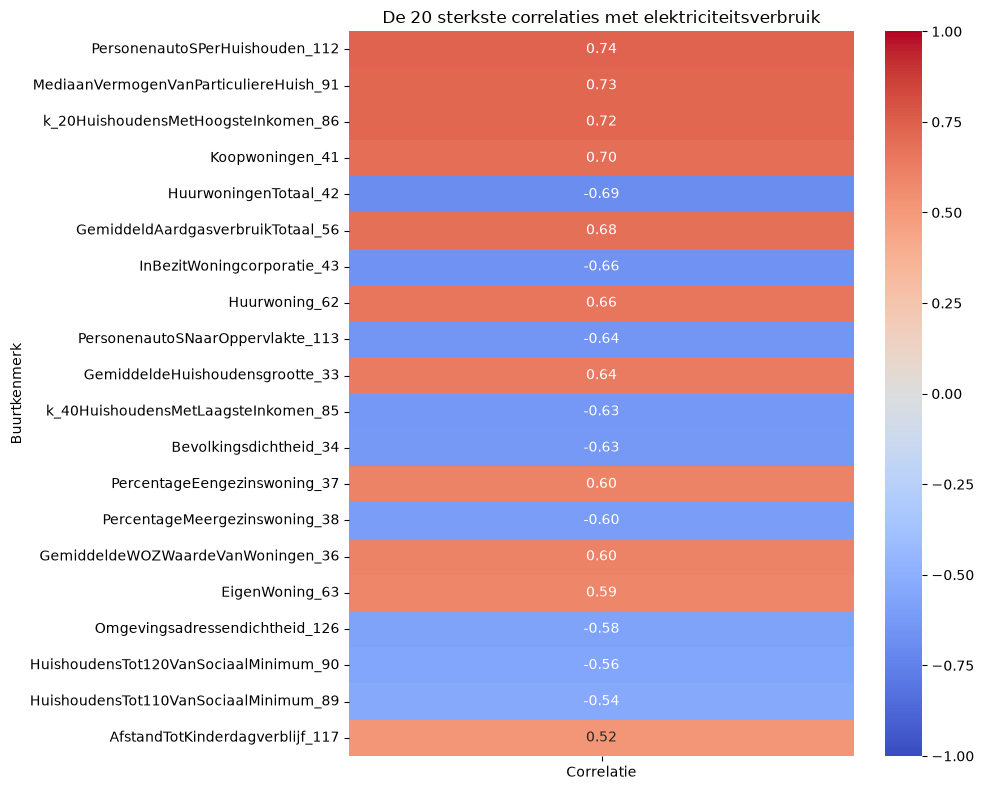

In [37]:
# De 20 sterkste correlaties tonen
heatmap_data = correlatietabel.dropna().head(20)

plt.figure(figsize=(10, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    yticklabels=True
)

plt.title("De 20 sterkste correlaties met elektriciteitsverbruik")
plt.ylabel("Buurtkenmerk")
plt.tight_layout()
plt.show()

### 4.7 Correlaties interpreteren

Personenauto’s per huishouden (0,736), huishoudensvermogen
(0,726) en het aandeel koopwoningen (0,695) hangen sterk
positief samen met elektriciteitsverbruik.

Het aandeel huurwoningen heeft een sterk negatief verband
(-0,694): buurten met meer huurwoningen hebben doorgaans
een lager gemiddeld elektriciteitsverbruik.

Deze kenmerken zijn mogelijke voorspellers vanwege hun
sterke samenhang. Koop- en huurpercentages bevatten wel
grotendeels dezelfde informatie.

Correlatie bewijst geen oorzaak. Met een model moeten we
nog testen hoe goed deze kenmerken daadwerkelijk voorspellen.